# 1. Dataset description

Przedstawiony zbiór zawiera zapisy EEG w systemie międzynarodowym 10/20 z badań podczas wykonywania zadania arytmetycznego (seryjne odejmowanie) oraz odpowiadające im nagrania referencyjne w spoczynku. Zbiór pochodzi z PhysioNet i nadaje się do analiz dynamiki mózgu przy obciążeniu poznawczym.

Źródło: Zyma I. et al. (2019), "Electroencephalograms during Mental Arithmetic Task Performance", Data / PhysioNet


## Uwaga - środowisko

- Wybierz kernel `Python (in-ynierka)` w Jupyter / VS Code (ten kernel został zarejestrowany w projekcie).
- Jeśli kernel nie ma zainstalowanych zależności, odpal w komórce poniżej (używa `%pip`, co instaluje w aktywnym kernelu):


## 2. Szybkie importy i konfiguracja

Tutaj importujemy moduły z pakietu `eegmat` (zawartość notebooka została przeniesiona do modułów).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import mne

from eegmat.io import load_all, read_one, parse_fname
from eegmat.preprocess import tidy, set_montage
from eegmat.dataset import make_dataset

mne.set_log_level('WARNING')

## 3. Lokalizacja danych

Skanujemy typowe ścieżki projektu aby znaleźć katalog z plikami EDF (jeśli masz dane w innym miejscu, zaktualizuj `candidates`).


In [2]:
def find_data_dir():
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0'),
        Path('physionet.org/files/eegmat/1.0.0'),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(f'No data dir found. Checked: {candidates}')

DATA_DIR = find_data_dir()
print('DATA_DIR =', DATA_DIR)

DATA_DIR = physionet.org/files/eegmat/1.0.0


## 4. (Opcjonalnie) wczytaj metadane `subject-info.csv` jeśli istnieją


In [3]:
info_path = DATA_DIR / 'subject-info.csv'
if info_path.exists():
    info = pd.read_csv(info_path)
    display(info.head())
else:
    print('Brak subject-info.csv w:', info_path)

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0


## 5. Wczytanie jednego pliku (szybkie sprawdzenie)

Pokazujemy podstawowe info o surowym nagraniu.


In [4]:
# Wczytaj przykładowy plik (Subject00_1.edf)
sample = read_one(DATA_DIR / 'Subject00_1.edf', preload=True)
sample = tidy(sample)
sample = set_montage(sample)
print(sample.info)
print('Channels:', sample.ch_names)
print('Sampling freq:', sample.info['sfreq'], 'Hz')
print('Duration (s):', sample.times[-1])

<Info | 9 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, F7, F8, T7, T8, C3, C4, P7, P8, P3, P4, O1, ...
 chs: 19 EEG, 1 misc, 1 ECG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.5 Hz
 lowpass: 45.0 Hz
 meas_date: 2011-01-01 00:00:00 UTC
 nchan: 21
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: 0, sex: 1, last_name: Subject0, birthday: 1990-01-01>
>
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'T7', 'T8', 'C3', 'C4', 'P7', 'P8', 'P3', 'P4', 'O1', 'O2', 'Fz', 'Cz', 'Pz', 'A2-A1', 'ECG ECG']
Sampling freq: 500.0 Hz
Duration (s): 181.998


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


## 6. Zbuduj dataset (epoki) i sprawdź rozmiary

Funkcja `make_dataset(records)` tworzy X, y, groups tak jak w poprzednim notebooku.


In [5]:
records = load_all(DATA_DIR, preload=False)  # preload można zmienić dla pamięciochłonnych operacji
print('loaded records:', len(records))
X, y, groups = make_dataset(records, epoch_len=4.0)
print('X shape:', X.shape)  # (n_epochs, n_channels, n_samples)
if y.size:
    print('y counts:', dict(zip(*np.unique(y, return_counts=True))))
else:
    print('y counts: empty')

loaded records: 67


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

X shape: (1969, 19, 2000)
y counts: {np.int64(0): np.int64(1459), np.int64(1): np.int64(510)}


## 7. Przykład: wykres PSD jednego nagrania

Uwaga: interaktywne wykresy mogą wymagać, żeby kernel miał dostęp do GUI (w VS Code wybierz odpowiedni backend matplotlib lub zapisz wykres).


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


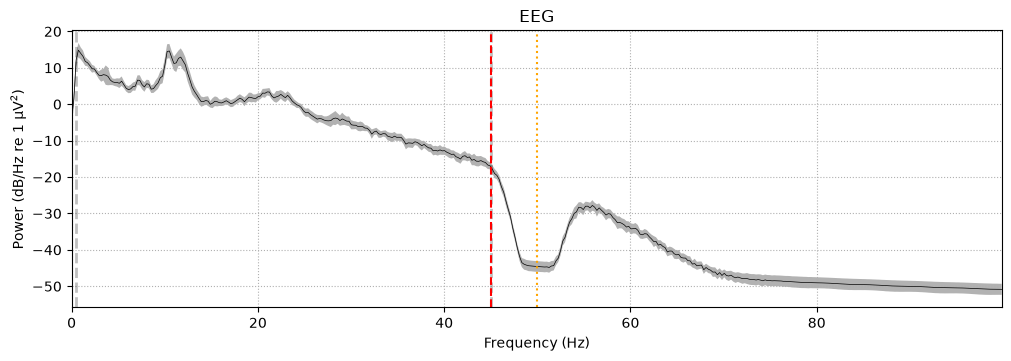

In [6]:
import matplotlib.pyplot as plt

raw_chk = set_montage(tidy(read_one(DATA_DIR / 'Subject00_1.edf', preload=True).copy()))
psd = raw_chk.compute_psd(picks='eeg', fmax=100)
ax = psd.plot(average=True, show=False)
plt.axvline(45, ls='--', c='r')
plt.axvline(50, ls=':', c='orange')
plt.show()

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=group_col, y=value_col, data=df, order=order, palette=palette)


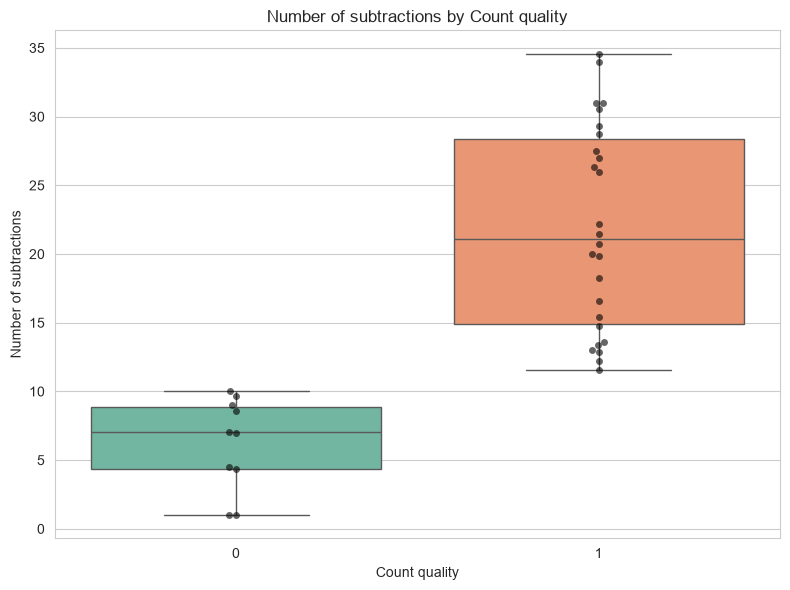

In [7]:
from eegmat.plots import boxplot_subtractions
fig = boxplot_subtractions(info, group_col='Count quality', value_col='Number of subtractions', invert=False)
fig

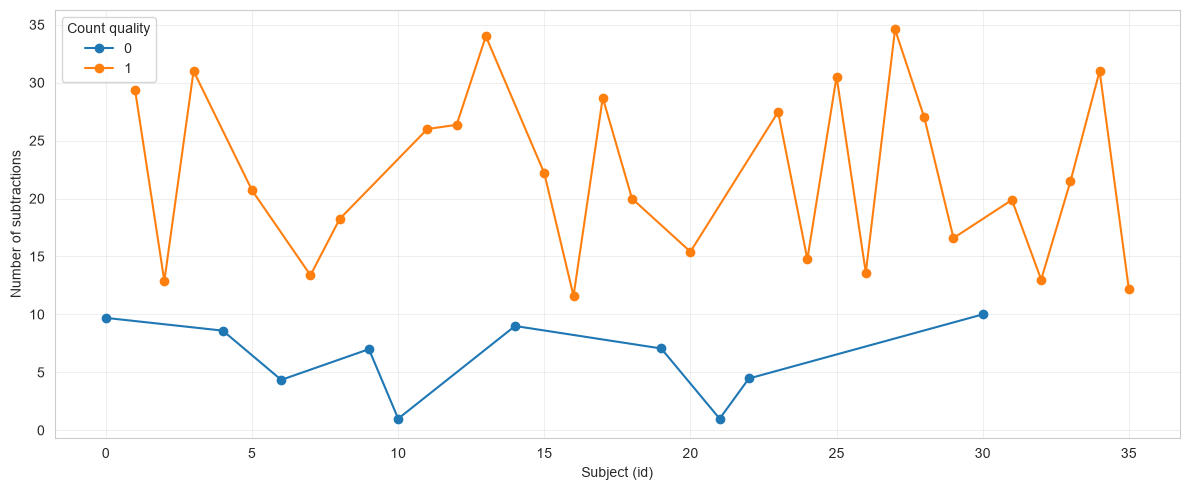

In [8]:
from eegmat.plots import snake_plot_subtractions
fig = snake_plot_subtractions(info, subject_col='Subject', value_col='Number of subtractions', group_col='Count quality')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=group_col, y=value_col, data=df, palette=palette, order=order, inner=None, cut=0)


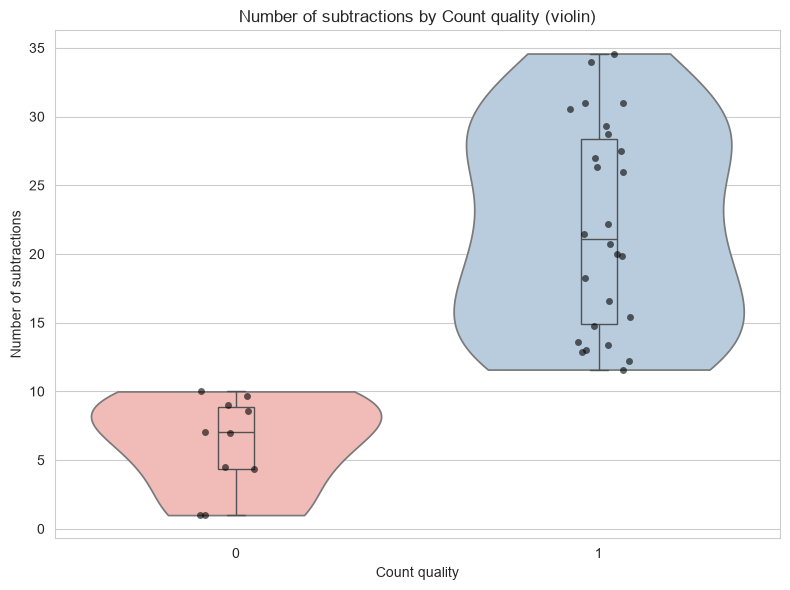

In [9]:
from eegmat.plots import violin_subtractions
fig = violin_subtractions(info, group_col='Count quality', value_col='Number of subtractions')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=group_col, y=value_col, data=df, palette=palette, order=order, inner=None, cut=0)


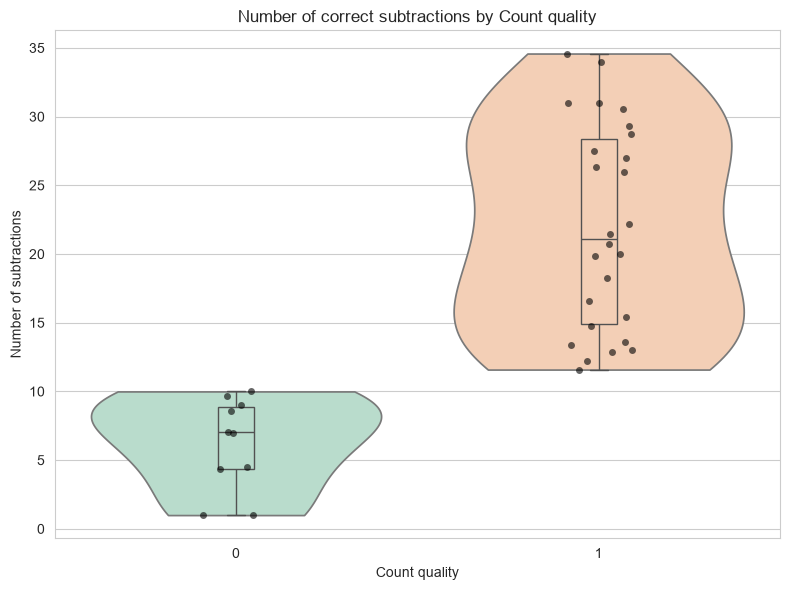

In [10]:
from eegmat.plots import violin_subtractions
fig = violin_subtractions(info,
                          group_col='Count quality',
                          value_col='Number of subtractions',
                          palette='Pastel2',
                          order=None,
                          show_box=True,
                          title='Number of correct subtractions by Count quality')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:128: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x=group_col, y=value_col, data=df, palette=palette)


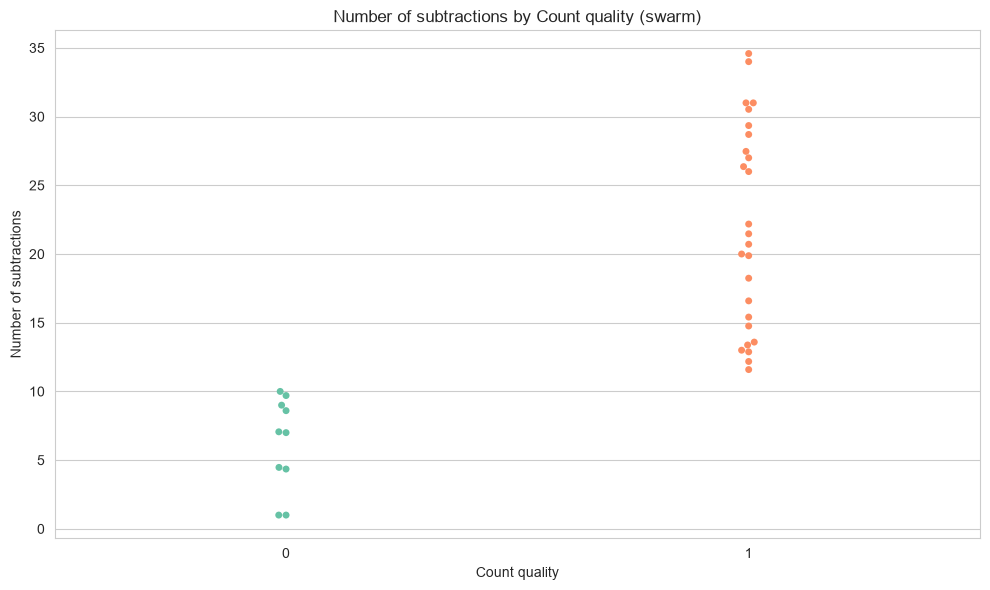

In [11]:
from eegmat.plots import swarm_plot_subtractions
fig = swarm_plot_subtractions(info,
                              group_col='Count quality',
                              value_col='Number of subtractions',
                              palette='Set2')
fig

In [12]:
# Uruchom w komórce notebooka (bez restartu kernela)
import importlib
import eegmat.splits as splits_mod
importlib.reload(splits_mod)
from eegmat.splits import split_subjects, plot_subject_allocation

In [13]:
from eegmat.splits import split_subjects, plot_subject_allocation

# standardowy przypadek
subs = [f'Subject{str(i).zfill(2)}' for i in range(36)]
assign = split_subjects(subs, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=0)
print({k: len(v) for k,v in assign.items()})

# mała liczba subjectów — wymuszamy min_size=1
subs2 = [f'Subject{str(i).zfill(2)}' for i in range(6)]
assign2 = split_subjects(subs2, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=1, min_size=1)
print({k: len(v) for k,v in assign2.items()})

# spec z bezwzględnymi liczbami
assign3 = split_subjects(subs2, spec={'train':3,'val':1,'dev':1,'holdout':1}, random_state=1)
print({k: len(v) for k,v in assign3.items()})

# narysuj alokację
fig = plot_subject_allocation(assign)

{'train': 21, 'val': 7, 'dev': 4, 'holdout': 4}
{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}
{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}


/Users/gsk/documents/projects/in-ynierka/eegmat/splits.py:318: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


In [14]:
subs2 = [f'Subject{str(i).zfill(2)}' for i in range(6)]
assign2 = split_subjects(subs2, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=1, min_size=1)
print({k: len(v) for k,v in assign2.items()})

{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}


In [15]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

info_df rows: 10


,Subject,Number of subtractions
0,Subject00,3
1,Subject01,0
2,Subject02,1
3,Subject03,0
4,Subject04,4


{'train': 6, 'val': 2, 'dev': 1, 'holdout': 1}


/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:202: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(sub[value_col].dropna(), label=label, color=colors[i], fill=fill)
/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:202: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(sub[value_col].dropna(), label=label, color=colors[i], fill=fill)


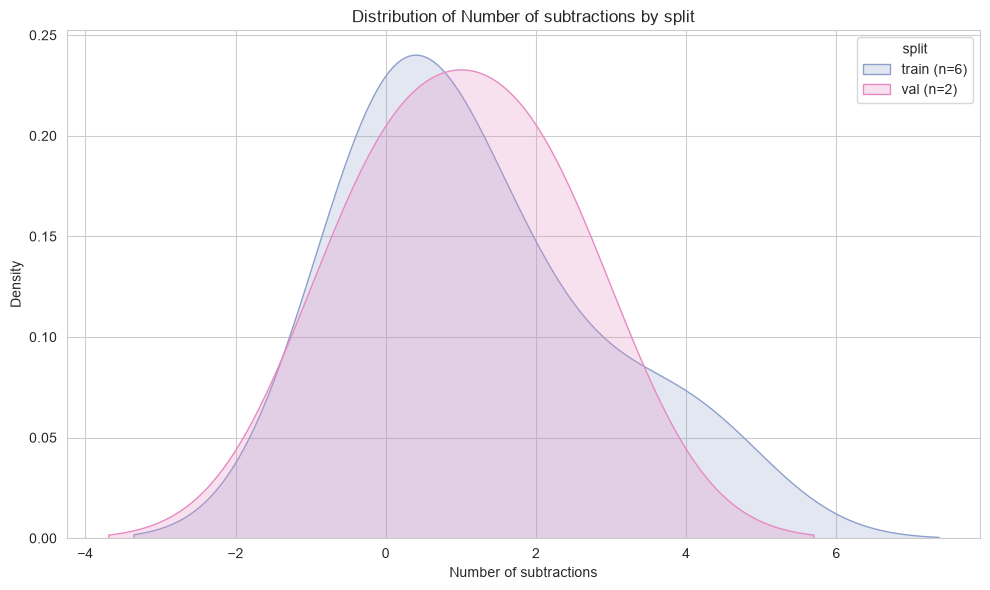

In [16]:
# Wklej do notebooka i uruchom
import importlib, os
import pandas as pd
import numpy as np

import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

# Przygotuj info_df jeśli jeszcze nie istnieje:
if 'info_df' not in globals():
    # 1) spróbuj wczytać CSV jeśli istnieje
    for path in ('subject-info.csv', 'datasets/subject-info.csv'):
        if os.path.exists(path):
            info_df = pd.read_csv(path)
            break
    else:
        # 2) fallback: spróbuj zebrać subjecty z eegmat (jeśli zainstalowane), inaczej demo
        try:
            from eegmat.io import load_all
            recs = load_all()
            # recs keys are (subject, state) tuples -> pobierz unikalne subjecty
            subs = sorted({f'Subject{int(k[0]):02d}' for k in recs.keys()})
        except Exception:
            subs = [f'Subject{str(i).zfill(2)}' for i in range(10)]
        # demo kolumna 'Number of subtractions' (zamień na realne dane jeśli masz)
        info_df = pd.DataFrame({
            'Subject': subs,
            'Number of subtractions': np.random.poisson(2, len(subs))
        })

print('info_df rows:', len(info_df))
display(info_df.head())

# Przygotuj assignments jeśli brak:
if 'assignments' not in globals():
    try:
        from eegmat.splits import split_subjects
        assignments = split_subjects(info_df['Subject'].tolist(),
                                     spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1},
                                     random_state=0, min_size=1)
    except Exception as e:
        # prosty równy podział jako fallback
        subs = info_df['Subject'].tolist()
        n = len(subs)
        assignments = {
            'train': subs[:int(n*0.6)],
            'val': subs[int(n*0.6):int(n*0.8)],
            'dev': subs[int(n*0.8):int(n*0.9)],
            'holdout': subs[int(n*0.9):]
        }

print({k: len(v) for k,v in assignments.items()})

# Rysuj: pojedynczy rozkład + rozkłady per-split
distribution_plot(info_df, value_col='Number of subtractions', kind='kde')
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions', kind='kde')


/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:280: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='split', y=value_col, data=merged, palette=palette, inner='quartile')


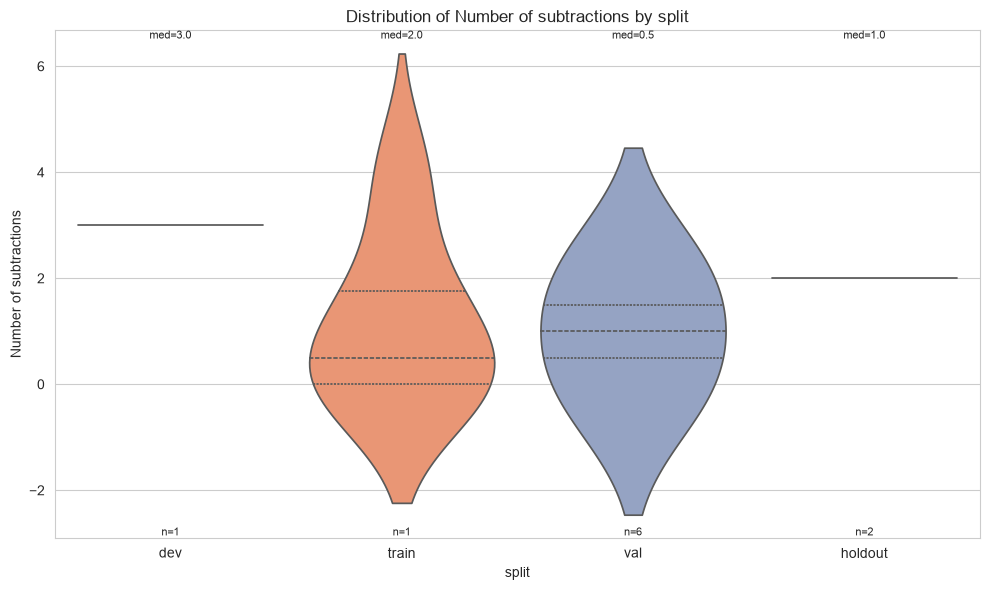

In [17]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

distribution_plot(info_df, value_col='Number of subtractions', kind='kde')
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions', kind='violin')

In [18]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_by_assignments

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:278: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='split', y=value_col, data=merged, palette=palette)


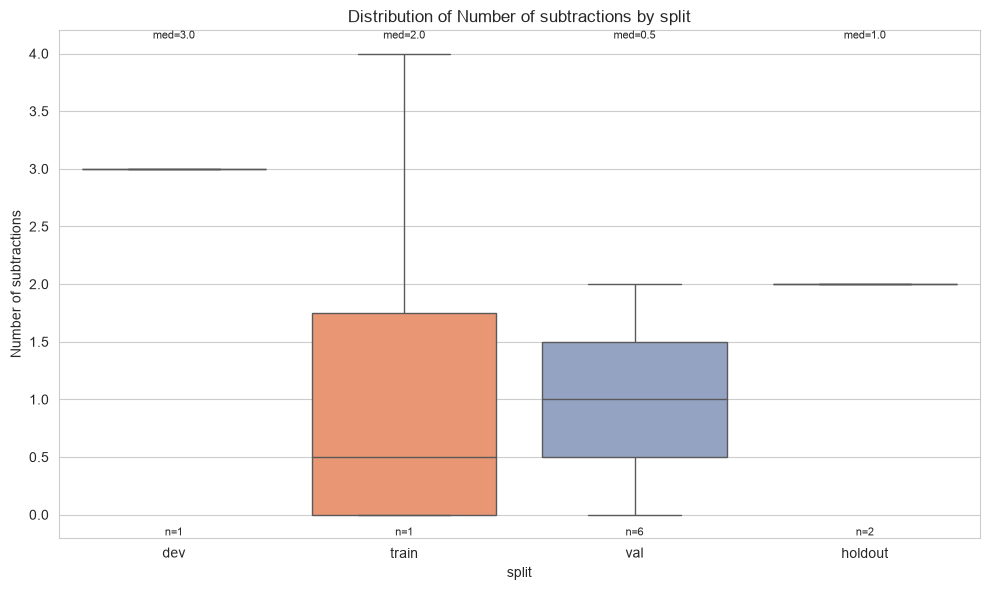

In [19]:
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions')

In [20]:
# Przeładuj moduł bez restartu kernela
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import quantity_quality_plot

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:359: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=quality_col, y=quantity_col, data=df, palette=palette, ax=ax1)
/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:365: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


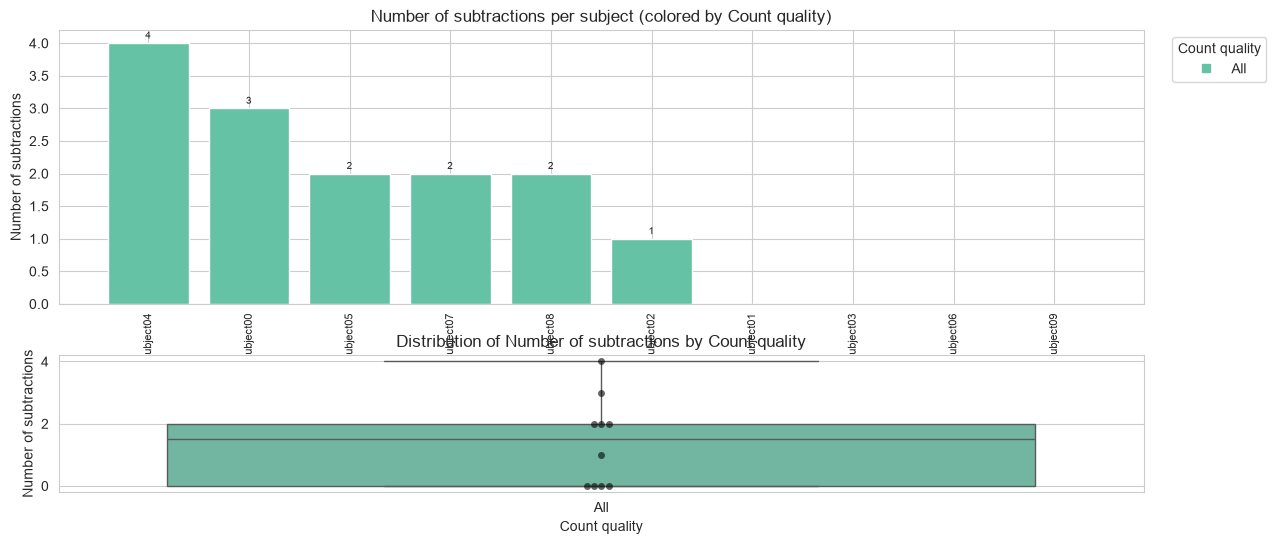

In [21]:
from eegmat.plots import quantity_quality_plot
fig = quantity_quality_plot(info_df,
                            subject_col='Subject',
                            quantity_col='Number of subtractions',
                            quality_col='Count quality')
fig

In [22]:
# Diagnostic + safe call for correct/incorrect plot
import importlib, re
from IPython.display import display
import pandas as pd
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import correct_incorrect_ratio_plot, quantity_quality_plot

def _find_subject_col(df):
    for c in df.columns:
        if 'subject' in c.lower():
            return c
    return df.columns[0] if len(df.columns) else None

def _find_col_by_candidates(df, candidates):
    cols = list(df.columns)
    lc = [c.lower() for c in cols]
    # direct substring match
    for cand in candidates:
        cand = cand.lower()
        for i, col in enumerate(lc):
            if cand in col:
                return cols[i]
    # looser normalized match
    norm = [''.join(re.findall(r'[a-z0-9]+', x.lower())) for x in cols]
    for cand in candidates:
        nc = ''.join(re.findall(r'[a-z0-9]+', cand.lower()))
        for i, col in enumerate(norm):
            if nc and nc in col:
                return cols[i]
    return None

def _try_total_minus_correct(df, subject_col, corr_col):
    total_candidates = ['total','n_total','n_subtractions','num_subtractions','numberofsubtractions','number of subtractions','n_subs','count']
    total_col = _find_col_by_candidates(df, total_candidates)
    if total_col:
        tmp = df[[subject_col, corr_col, total_col]].copy()
        tmp = tmp.rename(columns={corr_col: 'correct', total_col: 'total'})
        tmp['incorrect'] = tmp['total'] - tmp['correct']
        return tmp[[subject_col, 'correct', 'incorrect']]
    return None

# Start diagnostics
print('--- DIAGNOSTICS ---\n')

# info_df
if 'info_df' in globals() and isinstance(info_df, pd.DataFrame):
    print('info_df columns:', list(info_df.columns))
    display(info_df.head(5))
else:
    print('No info_df found or it is empty.')

print('\n')

# subtractions_df
if 'subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame):
    print('subtractions_df columns:', list(subtractions_df.columns))
    display(subtractions_df.head(5))
else:
    print('No subtractions_df found.')

print('\n--- ATTEMPTING AUTO-DETECTION ---\n')

# Try aggregated mode first
if 'info_df' in globals() and isinstance(info_df, pd.DataFrame) and not info_df.empty:
    df = info_df
    subject_col = _find_subject_col(df)
    corr_candidates = ['n_correct','num_correct','correct','n_corr','ncorrect','correct_count','n_success','success','true','ok','good']
    incorr_candidates = ['n_incorrect','num_incorrect','incorrect','n_wrong','wrong','fail','false','bad','n_error','errors']
    corr_col = _find_col_by_candidates(df, corr_candidates)
    incorr_col = _find_col_by_candidates(df, incorr_candidates)
    print('Detected subject_col =', subject_col)
    print('Detected candidate correct column =', corr_col)
    print('Detected candidate incorrect column =', incorr_col)

    if corr_col and incorr_col:
        print('Calling plot with detected aggregated columns...')
        fig = correct_incorrect_ratio_plot(df, subject_col=subject_col,
                                           correct_col=corr_col, incorrect_col=incorr_col,
                                           normalize=True, kind='stacked', annotate=True)
        display(fig)
    elif corr_col and not incorr_col:
        print('Found correct-like column but no incorrect-like column. Trying to derive incorrect = total - correct...')
        derived = _try_total_minus_correct(df, subject_col, corr_col)
        if derived is not None:
            display(derived.head(6))
            print('Derived counts found, calling plot...')
            fig = correct_incorrect_ratio_plot(derived, subject_col=subject_col,
                                               correct_col='correct', incorrect_col='incorrect',
                                               normalize=True, kind='stacked', annotate=True)
            display(fig)
        else:
            print('Could not derive incorrect. Available columns:', list(df.columns))
            raise RuntimeError('Provide both aggregated columns (correct/incorrect) in `info_df`, or provide `subtractions_df`.')
    elif incorr_col and not corr_col:
        print('Found incorrect-like column but no correct-like column. Trying to derive correct = total - incorrect...')
        derived = _try_total_minus_correct(df, subject_col, incorr_col)
        if derived is not None:
            display(derived.head(6))
            print('Derived counts found, calling plot...')
            fig = correct_incorrect_ratio_plot(derived, subject_col=subject_col,
                                               correct_col='correct', incorrect_col='incorrect',
                                               normalize=True, kind='stacked', annotate=True)
            display(fig)
        else:
            print('Could not derive correct. Available columns:', list(df.columns))
            raise RuntimeError('Provide both aggregated columns (correct/incorrect) in `info_df`, or provide `subtractions_df`.')
    else:
        print('No correct/incorrect-like columns detected in info_df.')
        # fall through to try long mode below

# Try long mode if present
if 'subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame) and not subtractions_df.empty:
    s = subtractions_df
    subj_col_long = _find_subject_col(s)
    flag_candidates = ['correct','is_correct','success','ok','accepted','label_correct','true','quality','status']
    flag_col = _find_col_by_candidates(s, flag_candidates)
    print('Long table detected. subject_col =', subj_col_long)
    print('Detected candidate correctness/quality column =', flag_col)
    if flag_col:
        print('Calling plot using long subtractions_df and flag_col =', flag_col)
        fig = correct_incorrect_ratio_plot(None, subject_col=subj_col_long, subtractions_df=s, correct_flag_col=flag_col, kind='stacked', normalize=True, annotate=True)
        display(fig)
    else:
        print('No correctness-like column detected in subtractions_df. Available columns:', list(s.columns))
        raise RuntimeError('Provide a correctness column (0/1 or boolean) in `subtractions_df`, or aggregated counts in `info_df`.')

# If we reached here without plotting, give final actionable message
if not ('info_df' in globals() and isinstance(info_df, pd.DataFrame) and (
        (_find_col_by_candidates(info_df, ['correct','n_correct','num_correct']) and _find_col_by_candidates(info_df, ['incorrect','n_incorrect','num_incorrect'])) or
        _find_col_by_candidates(info_df, ['total','n_subtractions','num_subtractions']))) and not ('subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame)):
    print('\\nACTIONABLE: To produce the correct/incorrect plot, do one of the following:\\n'
          '- In `info_df` provide two columns with per-subject counts, e.g. `n_correct` and `n_incorrect` (or `total` + `n_correct`).\\n'
          '- OR provide `subtractions_df` (one row per subtraction) containing a subject column and a correctness flag column (0/1 or boolean) such as `correct` or `is_correct`.\\n'
          'If you want, paste here the output of `list(info_df.columns)` and `list(subtractions_df.columns)` and I will tell the exact names to pass.')

--- DIAGNOSTICS ---

info_df columns: ['Subject', 'Number of subtractions']


,Subject,Number of subtractions
0,Subject00,3
1,Subject01,0
2,Subject02,1
3,Subject03,0
4,Subject04,4




No subtractions_df found.

--- ATTEMPTING AUTO-DETECTION ---

Detected subject_col = Subject
Detected candidate correct column = None
Detected candidate incorrect column = None
No correct/incorrect-like columns detected in info_df.
\nACTIONABLE: To produce the correct/incorrect plot, do one of the following:\n- In `info_df` provide two columns with per-subject counts, e.g. `n_correct` and `n_incorrect` (or `total` + `n_correct`).\n- OR provide `subtractions_df` (one row per subtraction) containing a subject column and a correctness flag column (0/1 or boolean) such as `correct` or `is_correct`.\nIf you want, paste here the output of `list(info_df.columns)` and `list(subtractions_df.columns)` and I will tell the exact names to pass.


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


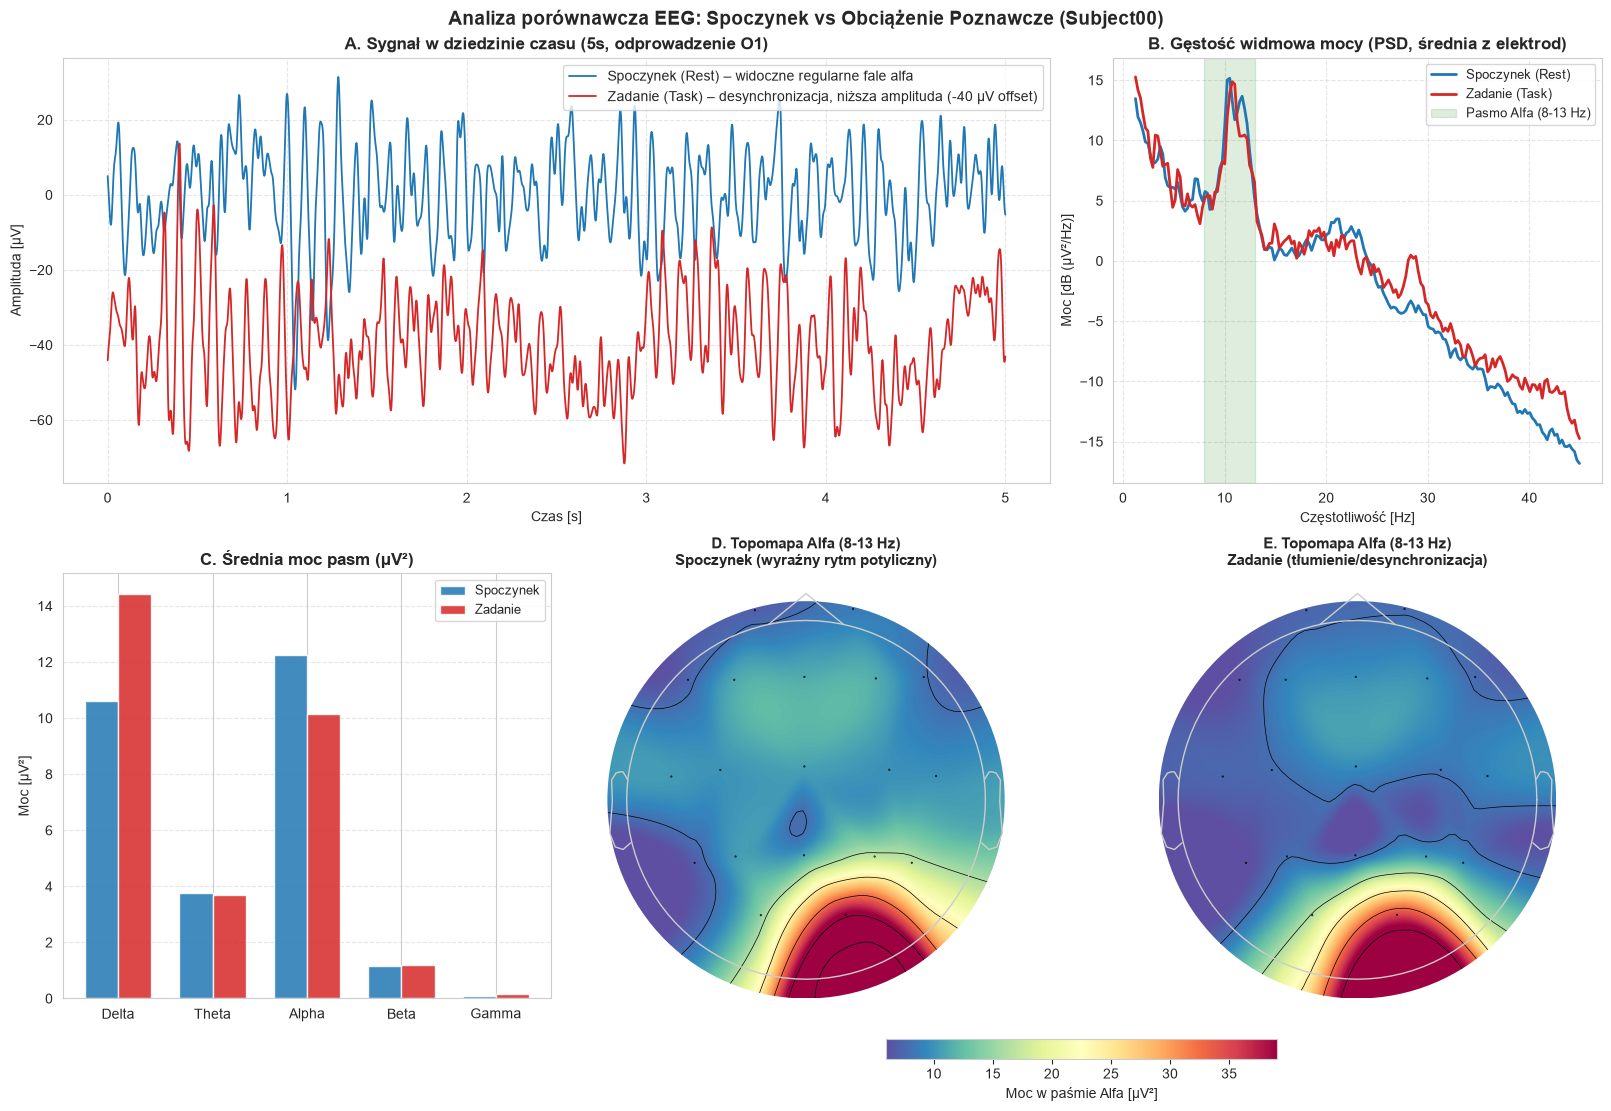

In [24]:
# -------------------------------------------------------------------------------------
# Porównanie stanu spoczynku (Rest, *_1.edf) i zadania arytmetycznego (Task, *_2.edf)
# Pokazuje co fizjologicznie dzieje się w sygnale EEG podczas wysiłku poznawczego.
# -------------------------------------------------------------------------------------
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import mne

from eegmat.io import read_one
from eegmat.preprocess import tidy, set_montage

# 1. Ścieżka do danych
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

# 2. Wczytanie i przygotowanie przykładowego badanego (Subject00)
subject_id = 'Subject00'
raw_rest = set_montage(tidy(read_one(DATA_DIR / f'{subject_id}_1.edf', preload=True)))
raw_task = set_montage(tidy(read_one(DATA_DIR / f'{subject_id}_2.edf', preload=True)))

raw_rest_eeg = raw_rest.copy().pick('eeg')
raw_task_eeg = raw_task.copy().pick('eeg')

# 3. Obliczenie gęstości widmowej mocy (PSD) w zakresie 1-45 Hz
psd_rest = raw_rest_eeg.compute_psd(fmin=1, fmax=45)
psd_task = raw_task_eeg.compute_psd(fmin=1, fmax=45)

freqs = psd_rest.freqs
data_rest = psd_rest.get_data()  # kształt: (n_channels, n_freqs)
data_task = psd_task.get_data()

# Definicje pasm częstotliwościowych
bands = {
    'Delta (1-4 Hz)': (1, 4),
    'Theta (4-8 Hz)': (4, 8),
    'Alpha (8-13 Hz)': (8, 13),
    'Beta (13-30 Hz)': (13, 30),
    'Gamma (30-45 Hz)': (30, 45)
}

def band_mean_power(psd_vals, f_arr, fmin, fmax):
    mask = (f_arr >= fmin) & (f_arr <= fmax)
    return psd_vals[:, mask].mean(axis=-1)

# 4. Tworzenie zestawu wykresów (Dashboard)
fig = plt.figure(figsize=(16, 11), constrained_layout=True)
gs = fig.add_gridspec(2, 3)

# Panel 1: Przebieg czasowy sygnału (5-sekundowe okno na elektrodzie potylicznej O1)
ax_time = fig.add_subplot(gs[0, :2])
sfreq = raw_rest.info['sfreq']
idx_start, idx_end = int(20 * sfreq), int(25 * sfreq)
time_vec = np.linspace(0, 5, idx_end - idx_start)

ch_name = 'O1'
data_r_ch = raw_rest_eeg.get_data(picks=ch_name)[0, idx_start:idx_end] * 1e6
data_t_ch = raw_task_eeg.get_data(picks=ch_name)[0, idx_start:idx_end] * 1e6

ax_time.plot(time_vec, data_r_ch, label='Spoczynek (Rest) – widoczne regularne fale alfa', color='#1f77b4', lw=1.3)
ax_time.plot(time_vec, data_t_ch - 40, label='Zadanie (Task) – desynchronizacja, niższa amplituda (-40 µV offset)', color='#d62728', lw=1.3)
ax_time.set_title(f'A. Sygnał w dziedzinie czasu (5s, odprowadzenie {ch_name})', fontsize=12, fontweight='bold')
ax_time.set_xlabel('Czas [s]')
ax_time.set_ylabel('Amplituda [µV]')
ax_time.grid(True, linestyle='--', alpha=0.5)
ax_time.legend(loc='upper right', frameon=True)

# Panel 2: Widmo gęstości mocy (PSD) - średnia ze wszystkich elektrod EEG
ax_psd = fig.add_subplot(gs[0, 2])
mean_psd_rest_db = 10 * np.log10(data_rest.mean(axis=0) * 1e12)
mean_psd_task_db = 10 * np.log10(data_task.mean(axis=0) * 1e12)

ax_psd.plot(freqs, mean_psd_rest_db, label='Spoczynek (Rest)', color='#1f77b4', lw=2)
ax_psd.plot(freqs, mean_psd_task_db, label='Zadanie (Task)', color='#d62728', lw=2)
ax_psd.axvspan(8, 13, color='forestgreen', alpha=0.15, label='Pasmo Alfa (8-13 Hz)')
ax_psd.set_title('B. Gęstość widmowa mocy (PSD, średnia z elektrod)', fontsize=12, fontweight='bold')
ax_psd.set_xlabel('Częstotliwość [Hz]')
ax_psd.set_ylabel('Moc [dB (µV²/Hz)]')
ax_psd.grid(True, linestyle='--', alpha=0.5)
ax_psd.legend(loc='upper right', fontsize=9, frameon=True)

# Panel 3: Średnia moc w poszczególnych pasmach EEG
ax_bands = fig.add_subplot(gs[1, 0])
bp_rest = [np.mean(band_mean_power(data_rest, freqs, fmin, fmax)) * 1e12 for fmin, fmax in bands.values()]
bp_task = [np.mean(band_mean_power(data_task, freqs, fmin, fmax)) * 1e12 for fmin, fmax in bands.values()]

x = np.arange(len(bands))
w = 0.35
ax_bands.bar(x - w/2, bp_rest, w, label='Spoczynek', color='#1f77b4', alpha=0.85)
ax_bands.bar(x + w/2, bp_task, w, label='Zadanie', color='#d62728', alpha=0.85)
ax_bands.set_xticks(x)
ax_bands.set_xticklabels([b.split(' ')[0] for b in bands.keys()])
ax_bands.set_title('C. Średnia moc pasm (µV²)', fontsize=12, fontweight='bold')
ax_bands.set_ylabel('Moc [µV²]')
ax_bands.grid(True, axis='y', linestyle='--', alpha=0.5)
ax_bands.legend(loc='upper right', fontsize=9, frameon=True)

# Panele 4 i 5: Topomapy rozkładu przestrzennego pasma Alfa (8-13 Hz)
alpha_mask = (freqs >= 8) & (freqs <= 13)
alpha_r = data_rest[:, alpha_mask].mean(axis=-1) * 1e12
alpha_t = data_task[:, alpha_mask].mean(axis=-1) * 1e12
vmax = max(alpha_r.max(), alpha_t.max())
vmin = min(alpha_r.min(), alpha_t.min())

ax_topo1 = fig.add_subplot(gs[1, 1])
im1, _ = mne.viz.plot_topomap(alpha_r, raw_rest_eeg.info, axes=ax_topo1, show=False, vlim=(vmin, vmax), cmap='Spectral_r')
ax_topo1.set_title('D. Topomapa Alfa (8-13 Hz)\nSpoczynek (wyraźny rytm potyliczny)', fontsize=11, fontweight='bold')

ax_topo2 = fig.add_subplot(gs[1, 2])
im2, _ = mne.viz.plot_topomap(alpha_t, raw_task_eeg.info, axes=ax_topo2, show=False, vlim=(vmin, vmax), cmap='Spectral_r')
ax_topo2.set_title('E. Topomapa Alfa (8-13 Hz)\nZadanie (tłumienie/desynchronizacja)', fontsize=11, fontweight='bold')

# Pasek skali dla topomap
cbar = fig.colorbar(im2, ax=[ax_topo1, ax_topo2], orientation='horizontal', fraction=0.046, pad=0.04)
cbar.set_label('Moc w paśmie Alfa [µV²]')

plt.suptitle(f'Analiza porównawcza EEG: Spoczynek vs Obciążenie Poznawcze ({subject_id})', fontsize=14, fontweight='bold')
plt.show()

findfont: Failed to find font weight medium, now using 400.


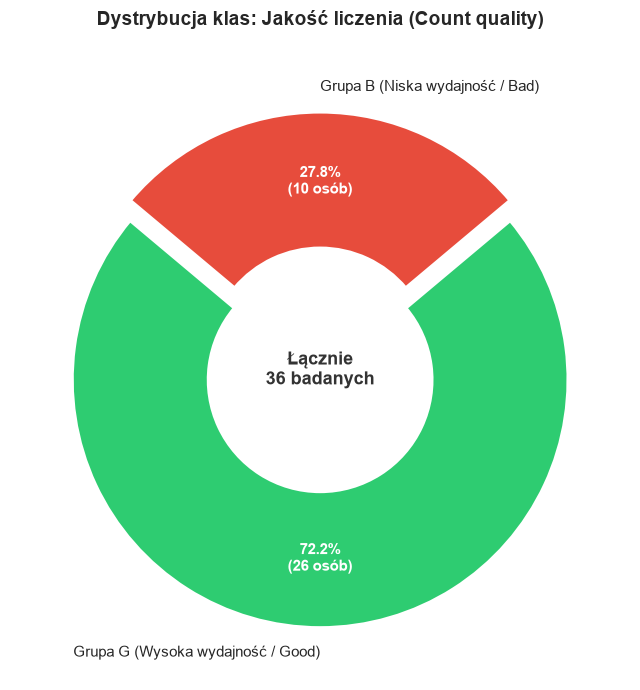

In [25]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Pobierz dane o badanych (korzysta ze zmiennej w sesji lub wczytuje plik z dysku)
if 'info' in globals() and isinstance(info, pd.DataFrame):
    df_info = info
elif 'info_df' in globals() and isinstance(info_df, pd.DataFrame):
    df_info = info_df
else:
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0/subject-info.csv'),
        Path('physionet.org/files/eegmat/1.0.0/subject-info.csv')
    ]
    df_info = next((pd.read_csv(p) for p in candidates if p.exists()), None)

if df_info is None:
    raise FileNotFoundError("Nie znaleziono danych 'subject-info.csv'.")

# 2. Zliczenie klas zadania 'Count quality'
counts = df_info['Count quality'].value_counts().rename({
    1: 'Grupa G (Wysoka wydajność / Good)',
    0: 'Grupa B (Niska wydajność / Bad)'
})

labels = counts.index
values = counts.values
colors = ['#2ecc71', '#e74c3c']  # zielony (Grupa G) i czerwony (Grupa B)
explode = (0.04, 0.04)

# Formatowanie etykiety: Procent + dokładna liczba osób
def make_autopct(vals):
    def fmt(pct):
        total = sum(vals)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val} osób)'
    return fmt

# 3. Rysowanie wykresu
fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    values,
    labels=labels,
    autopct=make_autopct(values),
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.72,
    wedgeprops={'width': 0.55, 'edgecolor': 'white', 'linewidth': 2.5},  # Styl Donut Chart
    textprops={'fontsize': 11, 'fontweight': 'medium'}
)

# Stylizacja tekstu wewnątrz wycinków
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

# Informacja w centrum pierścienia
ax.text(0, 0, f'Łącznie\n{sum(values)} badanych', ha='center', va='center',
        fontsize=13, fontweight='bold', color='#333333')

ax.set_title('Dystrybucja klas: Jakość liczenia (Count quality)',
             fontsize=14, fontweight='bold', pad=25)

plt.tight_layout()
plt.show()


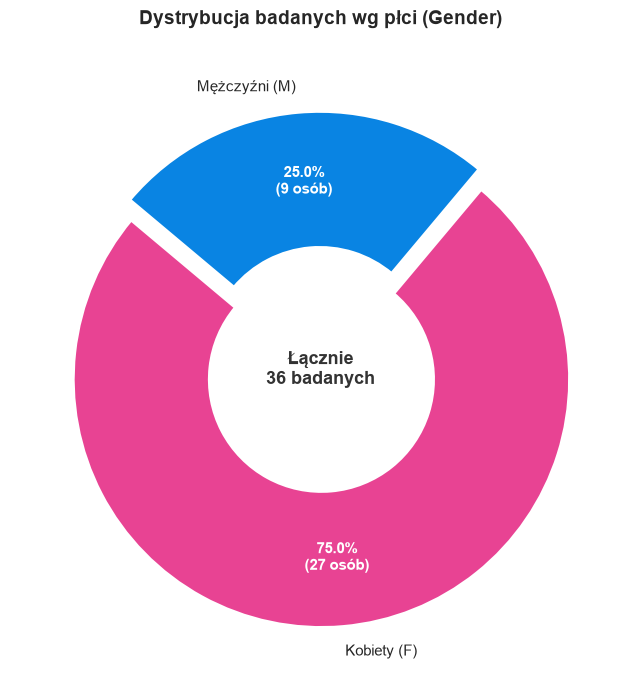

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Pobierz dane o badanych
if 'info' in globals() and isinstance(info, pd.DataFrame):
    df_info = info
elif 'info_df' in globals() and isinstance(info_df, pd.DataFrame):
    df_info = info_df
else:
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0/subject-info.csv'),
        Path('physionet.org/files/eegmat/1.0.0/subject-info.csv')
    ]
    df_info = next((pd.read_csv(p) for p in candidates if p.exists()), None)

if df_info is None:
    raise FileNotFoundError("Nie znaleziono danych 'subject-info.csv'.")

# 2. Zliczenie płci (F = Female, M = Male)
counts = df_info['Gender'].value_counts().rename({
    'F': 'Kobiety (F)',
    'M': 'Mężczyźni (M)'
})

labels = counts.index
values = counts.values
colors = ['#e84393', '#0984e3']  # Różowy (K) i Niebieski (M)
explode = (0.04, 0.04)

# Formatowanie etykiety: Procent + dokładna liczba osób
def make_autopct(vals):
    def fmt(pct):
        total = sum(vals)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val} osób)'
    return fmt

# 3. Rysowanie wykresu pierścieniowego
fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    values,
    labels=labels,
    autopct=make_autopct(values),
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.72,
    wedgeprops={'width': 0.55, 'edgecolor': 'white', 'linewidth': 2.5},
    textprops={'fontsize': 11, 'fontweight': 'medium'}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

# Tekst w środku pierścienia
ax.text(0, 0, f'Łącznie\n{sum(values)} badanych', ha='center', va='center',
        fontsize=13, fontweight='bold', color='#333333')

ax.set_title('Dystrybucja badanych wg płci (Gender)',
             fontsize=14, fontweight='bold', pad=25)

plt.tight_layout()
plt.show()


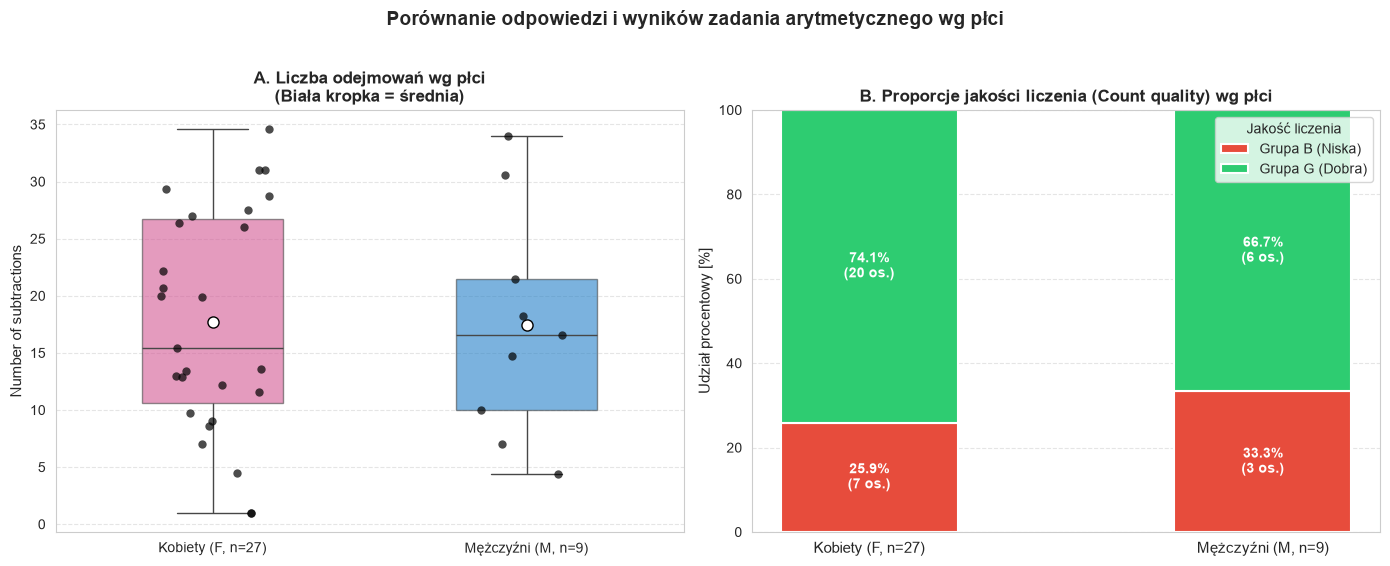

In [27]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Pobierz dane o badanych
if 'info' in globals() and isinstance(info, pd.DataFrame):
    df_info = info.copy()
elif 'info_df' in globals() and isinstance(info_df, pd.DataFrame):
    df_info = info_df.copy()
else:
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0/subject-info.csv'),
        Path('physionet.org/files/eegmat/1.0.0/subject-info.csv')
    ]
    df_info = next((pd.read_csv(p) for p in candidates if p.exists()), None)

if df_info is None:
    raise FileNotFoundError("Nie znaleziono danych 'subject-info.csv'.")

# 2. Przygotowanie czytelnych etykiet
df_plot = df_info.copy()
df_plot['Płeć'] = df_plot['Gender'].map({'F': 'Kobiety (F, n=27)', 'M': 'Mężczyźni (M, n=9)'})
df_plot['Jakość liczenia'] = df_plot['Count quality'].map({1: 'Grupa G (Dobra)', 0: 'Grupa B (Niska)'})

palette_gender = {'Kobiety (F, n=27)': '#e84393', 'Mężczyźni (M, n=9)': '#0984e3'}
colors_quality = {'Grupa B (Niska)': '#e74c3c', 'Grupa G (Dobra)': '#2ecc71'}

# 3. Tworzenie wykresów
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Liczba odejmowań (Rozkład ilościowy) ---
sns.boxplot(
    ax=axes[0], data=df_plot, x='Płeć', y='Number of subtractions',
    hue='Płeć', palette=palette_gender, legend=False,
    width=0.45, boxprops=dict(alpha=0.6), showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 8}
)
sns.stripplot(
    ax=axes[0], data=df_plot, x='Płeć', y='Number of subtractions',
    color='black', size=6, jitter=0.18, alpha=0.7
)

axes[0].set_title('A. Liczba odejmowań wg płci\n(Biała kropka = średnia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of subtractions', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5, axis='y')

# --- Panel 2: Jakość liczenia (Rozkład kategoryczny - Stacked 100%) ---
crosstab_pct = pd.crosstab(df_plot['Płeć'], df_plot['Jakość liczenia'], normalize='index')[['Grupa B (Niska)', 'Grupa G (Dobra)']] * 100
crosstab_raw = pd.crosstab(df_plot['Płeć'], df_plot['Jakość liczenia'])[['Grupa B (Niska)', 'Grupa G (Dobra)']]

bottom = np.zeros(len(crosstab_pct))
x_indices = np.arange(len(crosstab_pct))
bar_width = 0.45

for col in ['Grupa B (Niska)', 'Grupa G (Dobra)']:
    values_pct = crosstab_pct[col].values
    values_raw = crosstab_raw[col].values
    bars = axes[1].bar(x_indices, values_pct, bar_width, bottom=bottom,
                      label=col, color=colors_quality[col], edgecolor='white', linewidth=1.5)
    
    # Etykiety z procentem i liczbą osób wewnątrz słupków
    for idx, (rect, pct, raw) in enumerate(zip(bars, values_pct, values_raw)):
        if pct > 8:
            axes[1].text(rect.get_x() + rect.get_width() / 2, bottom[idx] + pct / 2,
                         f'{pct:.1f}%\n({raw} os.)',
                         ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    bottom += values_pct

axes[1].set_title('B. Proporcje jakości liczenia (Count quality) wg płci', fontsize=12, fontweight='bold')
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(crosstab_pct.index, fontsize=11)
axes[1].set_xlabel('')
axes[1].set_ylabel('Udział procentowy [%]', fontsize=11)
axes[1].set_ylim(0, 100)
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')
axes[1].legend(title='Jakość liczenia', loc='upper right', frameon=True)

plt.suptitle('Porównanie odpowiedzi i wyników zadania arytmetycznego wg płci', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


-> Wylosowano próbkę: Subject20 | Płeć: Kobieta, Wiek: 17, Dobra jakość (Grupa G), Wynik: 15.41 operacji


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


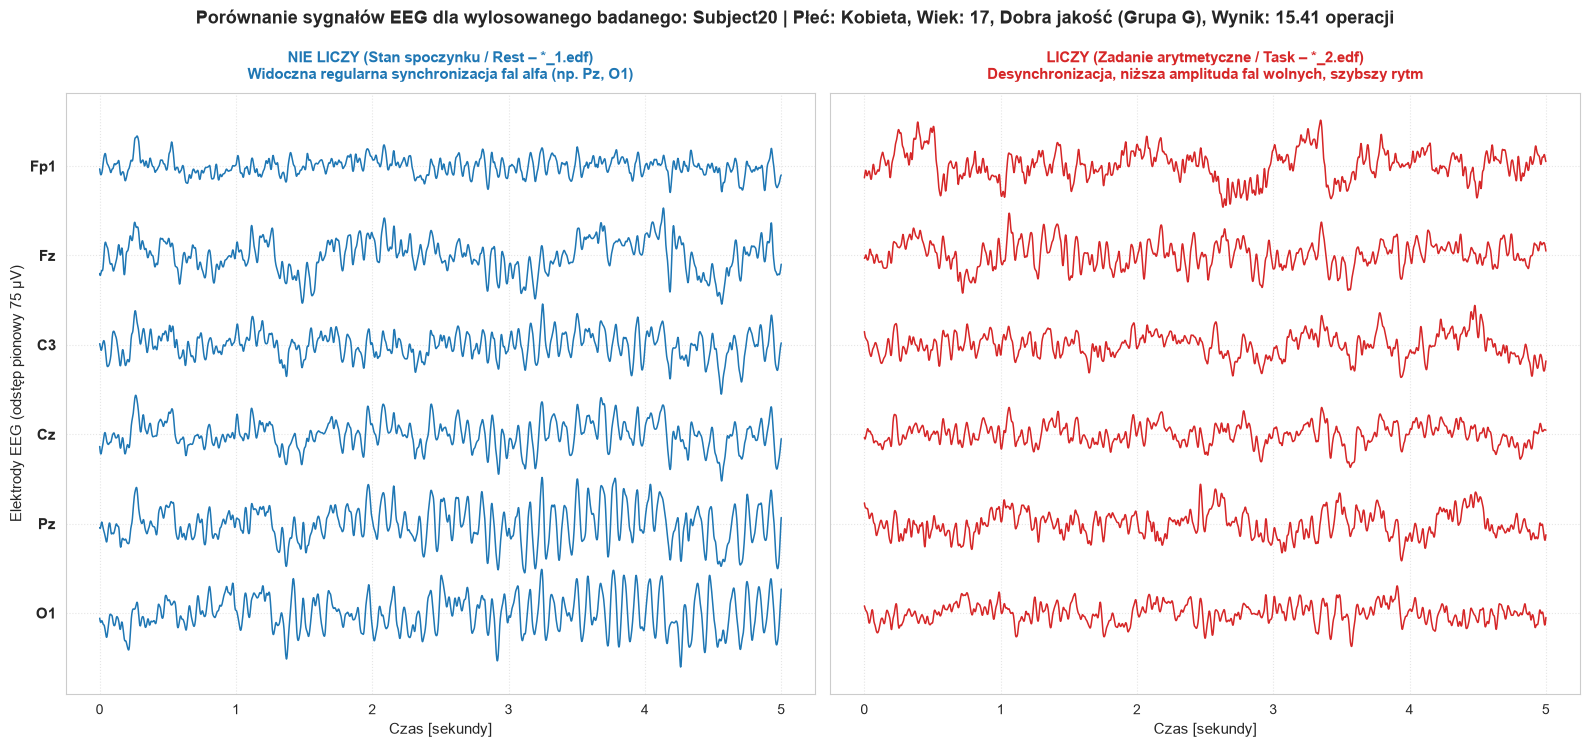

In [28]:
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mne

from eegmat.io import read_one
from eegmat.preprocess import tidy, set_montage

# 1. Ścieżka do danych i metadane
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

# Wczytanie metadanych jeśli są dostępne
info_file = DATA_DIR / 'subject-info.csv'
info_df = pd.read_csv(info_file) if info_file.exists() else None

# 2. Losowy wybór badanego (Subject00 - Subject35)
all_subjects = sorted(list(set(f.stem.split('_')[0] for f in DATA_DIR.glob('Subject*_1.edf'))))
subj = random.choice(all_subjects)

# Informacje o wylosowanej osobie
meta_txt = ""
if info_df is not None and subj in info_df['Subject'].values:
    row = info_df[info_df['Subject'] == subj].iloc[0]
    q_label = "Dobra jakość (Grupa G)" if row['Count quality'] == 1 else "Niska jakość (Grupa B)"
    p_label = "Kobieta" if row['Gender'] == 'F' else "Mężczyzna"
    meta_txt = f" | Płeć: {p_label}, Wiek: {row['Age']}, {q_label}, Wynik: {row['Number of subtractions']} operacji"

print(f"-> Wylosowano próbkę: {subj}{meta_txt}")

# 3. Wczytanie sygnałów (spoczynek _1 vs liczenie _2)
raw_rest = set_montage(tidy(read_one(DATA_DIR / f'{subj}_1.edf', preload=True)))
raw_task = set_montage(tidy(read_one(DATA_DIR / f'{subj}_2.edf', preload=True)))

# Wybór kluczowych elektrod w osi przód-tył (Frontal -> Central -> Parietal -> Occipital)
selected_channels = ['Fp1', 'Fz', 'C3', 'Cz', 'Pz', 'O1']
channels = [ch for ch in selected_channels if ch in raw_rest.ch_names]

# 4. Wycięcie wspólnego okna czasowego (np. 5 sekund ze środka nagrania)
sfreq = raw_rest.info['sfreq']
t_start = 15.0       # start w 15. sekundzie (ustabilizowany sygnał)
duration = 5.0      # długość okna 5s
idx_start = int(t_start * sfreq)
idx_end = int((t_start + duration) * sfreq)
times = np.linspace(0, duration, idx_end - idx_start)

# 5. Rysowanie wielokanałowego zapisu EEG obok siebie
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True)
spacing = 75  # pionowy odstęp między kanałami [µV]

for i, ch in enumerate(reversed(channels)):
    offset = i * spacing
    # Przeliczenie na mikrowolty (µV)
    sig_rest = raw_rest.get_data(picks=ch)[0, idx_start:idx_end] * 1e6 + offset
    sig_task = raw_task.get_data(picks=ch)[0, idx_start:idx_end] * 1e6 + offset
    
    axes[0].plot(times, sig_rest, color='#1f77b4', lw=1.1)
    axes[1].plot(times, sig_task, color='#d62728', lw=1.1)

y_ticks = [i * spacing for i in range(len(channels))]
y_labels = list(reversed(channels))

# Formatowanie paneli
axes[0].set_title('NIE LICZY (Stan spoczynku / Rest – *_1.edf)\nWidoczna regularna synchronizacja fal alfa (np. Pz, O1)',
                  fontsize=11, fontweight='bold', color='#1f77b4', pad=10)
axes[1].set_title('LICZY (Zadanie arytmetyczne / Task – *_2.edf)\nDesynchronizacja, niższa amplituda fal wolnych, szybszy rytm',
                  fontsize=11, fontweight='bold', color='#d62728', pad=10)

for ax in axes:
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=11, fontweight='bold')
    ax.set_xlabel('Czas [sekundy]', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.5)

axes[0].set_ylabel('Elektrody EEG (odstęp pionowy 75 µV)', fontsize=11)

plt.suptitle(f'Porównanie sygnałów EEG dla wylosowanego badanego: {subj}{meta_txt}',
             fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


-> Analiza numeryczna i spektrogram dla: Subject20 (Płeć: F, Wiek: 17, Grupa: G) na odprowadzeniu O1


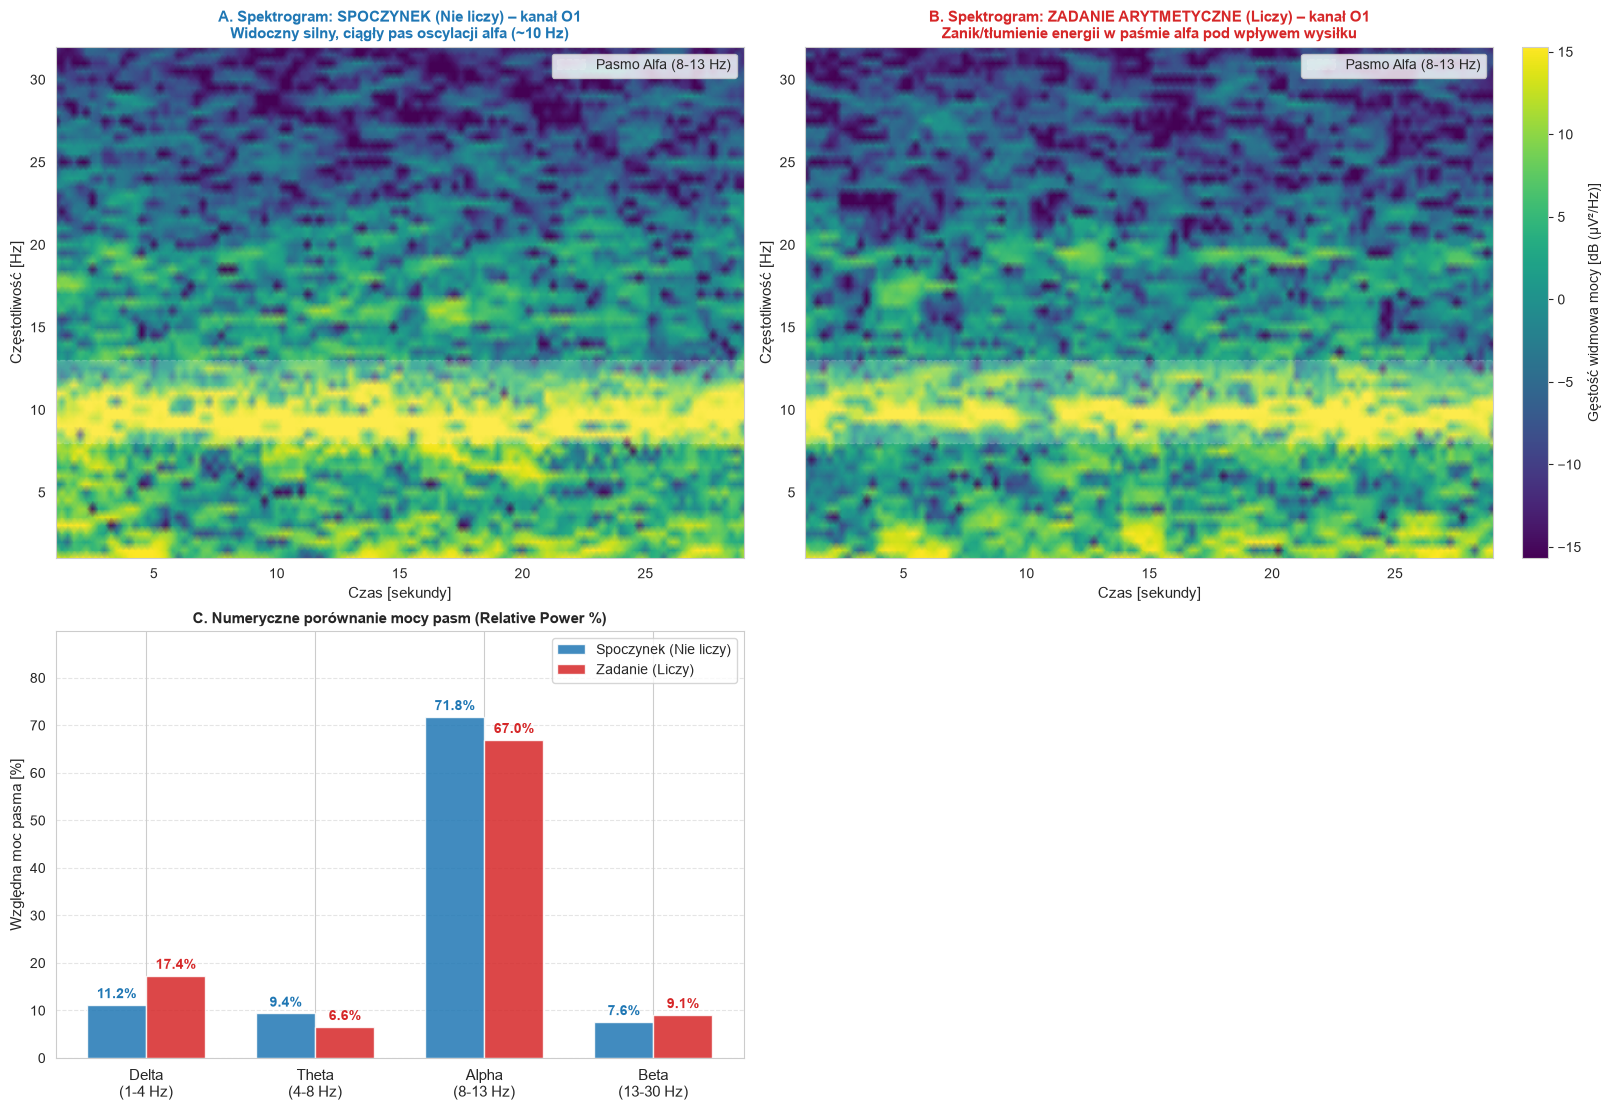

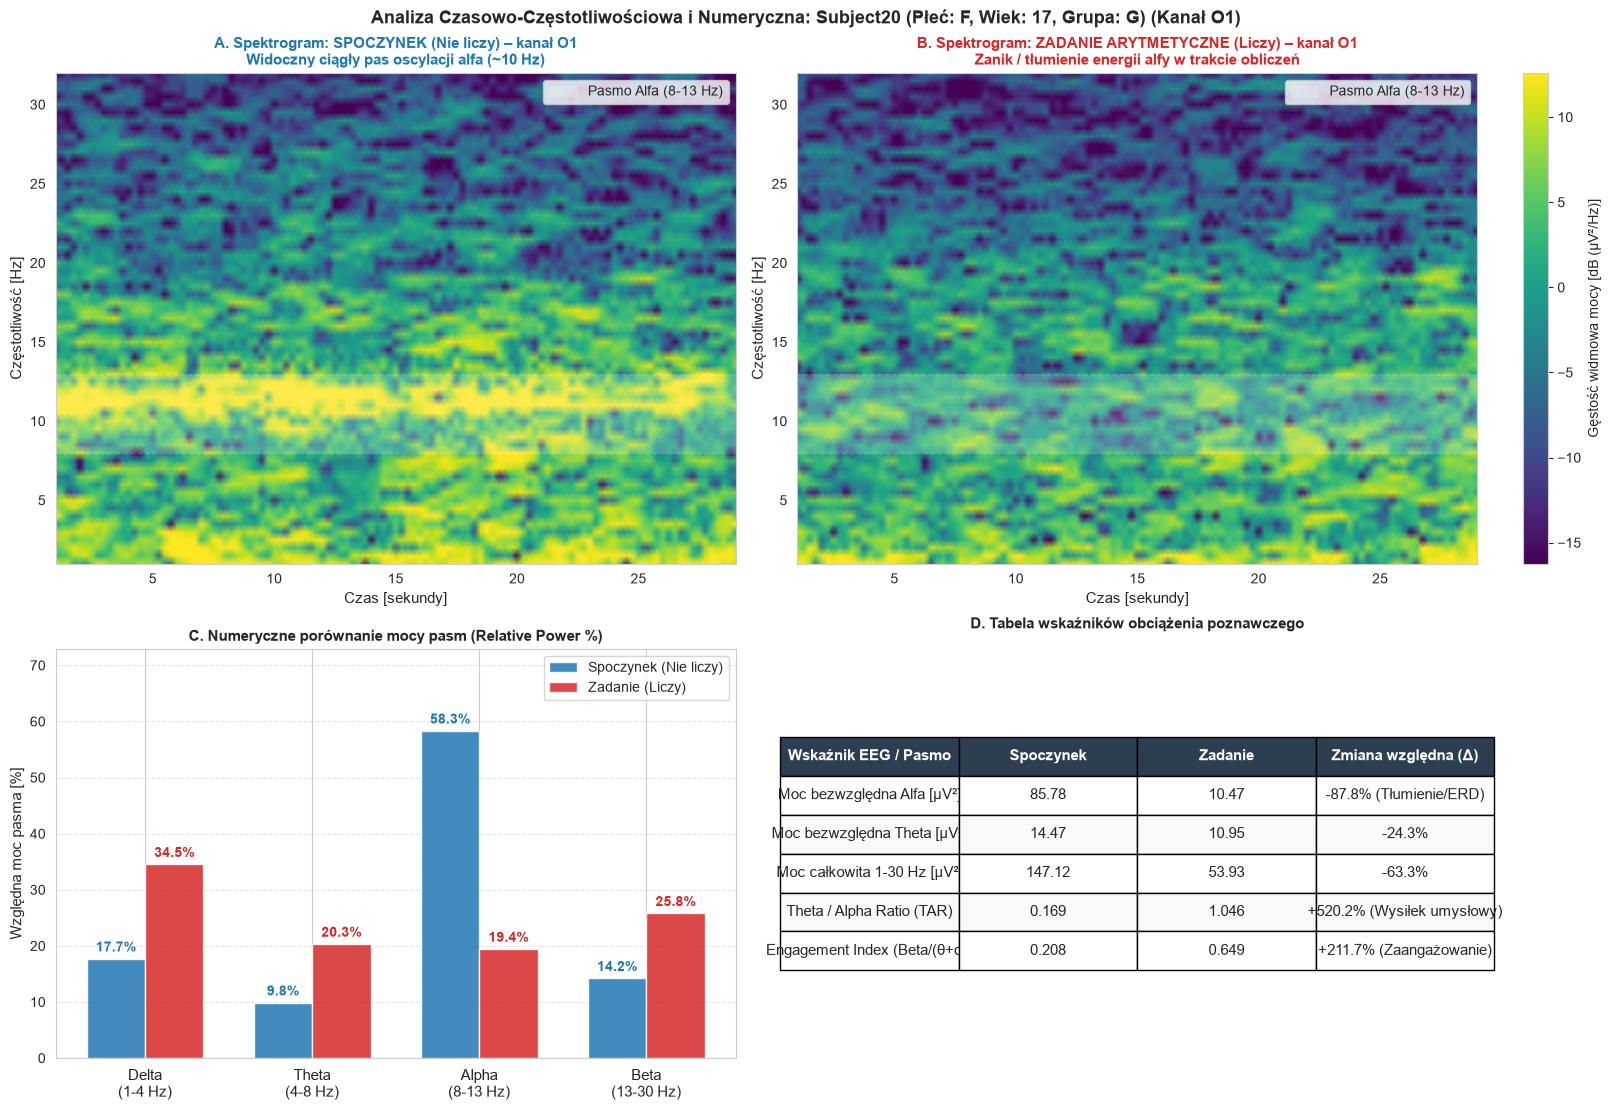

In [33]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import trapezoid
import pandas as pd
import mne

from eegmat.io import read_one
from eegmat.preprocess import tidy, set_montage

# 1. Ścieżka do danych i lista poprawnych par plików
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

s1 = set(p.stem.replace('_1', '') for p in DATA_DIR.glob('*_1.edf'))
s2 = set(p.stem.replace('_2', '') for p in DATA_DIR.glob('*_2.edf'))
paired_subjects = sorted(list(s1.intersection(s2)))

# Możesz wpisać konkretnego badanego (np. subj = 'Subject23') lub zostawić losowanie:
subj = random.choice(paired_subjects)
ch = 'O1'  # Odprowadzenie potyliczne (kluczowe dla rytmu alfa)

info_file = DATA_DIR / 'subject-info.csv'
info_df = pd.read_csv(info_file) if info_file.exists() else None
meta_txt = ""
if info_df is not None and subj in info_df['Subject'].values:
    row = info_df[info_df['Subject'] == subj].iloc[0]
    meta_txt = f" (Płeć: {row['Gender']}, Wiek: {row['Age']}, Grupa: {'G' if row['Count quality']==1 else 'B'})"

print(f"-> Analiza numeryczna i spektrogram dla: {subj}{meta_txt} na odprowadzeniu {ch}")

# 2. Wczytanie sygnałów
raw_rest = set_montage(tidy(read_one(DATA_DIR / f'{subj}_1.edf', preload=True)))
raw_task = set_montage(tidy(read_one(DATA_DIR / f'{subj}_2.edf', preload=True)))

sfreq = raw_rest.info['sfreq']
t_dur = 30.0  # 30-sekundowe okno
sig_r = raw_rest.get_data(picks=ch)[0, :int(t_dur * sfreq)] * 1e6  # µV
sig_t = raw_task.get_data(picks=ch)[0, :int(t_dur * sfreq)] * 1e6

# 3. Obliczenie spektrogramów (STFT)
nperseg = int(sfreq * 2)      # 2-sekundowe okno (rozdzielczość 0.5 Hz)
noverlap = int(sfreq * 1.75)  # 87.5% zakładki
f_r, t_r, Sxx_r = signal.spectrogram(sig_r, fs=sfreq, nperseg=nperseg, noverlap=noverlap)
f_t, t_t, Sxx_t = signal.spectrogram(sig_t, fs=sfreq, nperseg=nperseg, noverlap=noverlap)

f_mask = (f_r >= 1) & (f_r <= 32)
freqs_sub = f_r[f_mask]
Sxx_r_db = 10 * np.log10(Sxx_r[f_mask, :])
Sxx_t_db = 10 * np.log10(Sxx_t[f_mask, :])

vmin = min(np.percentile(Sxx_r_db, 5), np.percentile(Sxx_t_db, 5))
vmax = max(np.percentile(Sxx_r_db, 95), np.percentile(Sxx_t_db, 95))

# 4. Obliczenie mocy pasm metodą Welcha do porównania numerycznego
f_pw_r, psd_r = signal.welch(sig_r, fs=sfreq, nperseg=int(sfreq * 2))
f_pw_t, psd_t = signal.welch(sig_t, fs=sfreq, nperseg=int(sfreq * 2))

bands = {
    'Delta': (1, 4),
    'Theta': (4, 8),
    'Alpha': (8, 13),
    'Beta': (13, 30)
}

def get_band_metrics(f, p):
    mask_tot = (f >= 1) & (f <= 30)
    tot = trapezoid(p[mask_tot], f[mask_tot])
    abs_p, rel_p = {}, {}
    for name, (fmin, fmax) in bands.items():
        m = (f >= fmin) & (f <= fmax)
        val = trapezoid(p[m], f[m])
        abs_p[name] = val
        rel_p[name] = (val / tot) * 100
    return abs_p, rel_p

abs_r, rel_r = get_band_metrics(f_pw_r, psd_r)
abs_t, rel_t = get_band_metrics(f_pw_t, psd_t)

# Wskaźniki kognitywne
tar_r = abs_r['Theta'] / abs_r['Alpha']
tar_t = abs_t['Theta'] / abs_t['Alpha']
tar_chg = ((tar_t - tar_r) / tar_r) * 100

eng_r = abs_r['Beta'] / (abs_r['Theta'] + abs_r['Alpha'])
eng_t = abs_t['Beta'] / (abs_t['Theta'] + abs_t['Alpha'])
eng_chg = ((eng_t - eng_r) / eng_r) * 100

erd_alpha = ((abs_t['Alpha'] - abs_r['Alpha']) / abs_r['Alpha']) * 100

# 5. Rysowanie Dashboardu
fig = plt.figure(figsize=(16, 11), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0])

# --- Panel A: Spektrogram Spoczynku ---
ax_spec_r = fig.add_subplot(gs[0, 0])
c_r = ax_spec_r.pcolormesh(t_r, freqs_sub, Sxx_r_db, shading='gouraud', cmap='viridis', vmin=vmin, vmax=vmax)
ax_spec_r.axhspan(8, 13, facecolor='white', alpha=0.18, linestyle='--', edgecolor='white', label='Pasmo Alfa (8-13 Hz)')
ax_spec_r.set_title(f'A. Spektrogram: SPOCZYNEK (Nie liczy) – kanał {ch}\nWidoczny ciągły pas oscylacji alfa (~10 Hz)',
                    fontsize=11, fontweight='bold', color='#1f77b4')
ax_spec_r.set_ylabel('Częstotliwość [Hz]', fontsize=11)
ax_spec_r.set_xlabel('Czas [sekundy]', fontsize=11)
ax_spec_r.set_ylim(1, 32)
ax_spec_r.legend(loc='upper right', frameon=True)

# --- Panel B: Spektrogram Zadania ---
ax_spec_t = fig.add_subplot(gs[0, 1])
c_t = ax_spec_t.pcolormesh(t_t, freqs_sub, Sxx_t_db, shading='gouraud', cmap='viridis', vmin=vmin, vmax=vmax)
ax_spec_t.axhspan(8, 13, facecolor='white', alpha=0.18, linestyle='--', edgecolor='white', label='Pasmo Alfa (8-13 Hz)')
ax_spec_t.set_title(f'B. Spektrogram: ZADANIE ARYTMETYCZNE (Liczy) – kanał {ch}\nZanik / tłumienie energii alfy w trakcie obliczeń',
                    fontsize=11, fontweight='bold', color='#d62728')
ax_spec_t.set_ylabel('Częstotliwość [Hz]', fontsize=11)
ax_spec_t.set_xlabel('Czas [sekundy]', fontsize=11)
ax_spec_t.set_ylim(1, 32)
ax_spec_t.legend(loc='upper right', frameon=True)

cb = fig.colorbar(c_t, ax=[ax_spec_r, ax_spec_t], orientation='vertical', fraction=0.02, pad=0.02)
cb.set_label('Gęstość widmowa mocy [dB (µV²/Hz)]', fontsize=10)

# --- Panel C: Względna moc pasm ---
ax_bar = fig.add_subplot(gs[1, 0])
b_keys = list(bands.keys())
x = np.arange(len(b_keys))
w = 0.35
r_vals = [rel_r[k] for k in b_keys]
t_vals = [rel_t[k] for k in b_keys]

b1 = ax_bar.bar(x - w/2, r_vals, w, label='Spoczynek (Nie liczy)', color='#1f77b4', alpha=0.85)
b2 = ax_bar.bar(x + w/2, t_vals, w, label='Zadanie (Liczy)', color='#d62728', alpha=0.85)

for rect in b1:
    h = rect.get_height()
    ax_bar.text(rect.get_x() + rect.get_width()/2, h + 0.8, f'{h:.1f}%',
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1f77b4')

for rect in b2:
    h = rect.get_height()
    ax_bar.text(rect.get_x() + rect.get_width()/2, h + 0.8, f'{h:.1f}%',
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#d62728')

ax_bar.set_xticks(x)
ax_bar.set_xticklabels([f'{k}\n({bands[k][0]}-{bands[k][1]} Hz)' for k in b_keys], fontsize=11)
ax_bar.set_ylabel('Względna moc pasma [%]', fontsize=11)
ax_bar.set_ylim(0, max(max(r_vals), max(t_vals)) * 1.25)
ax_bar.set_title('C. Numeryczne porównanie mocy pasm (Relative Power %)', fontsize=11, fontweight='bold')
ax_bar.grid(True, axis='y', linestyle='--', alpha=0.5)
ax_bar.legend(loc='upper right', frameon=True)

# --- Panel D: Numeryczna tabela wskaźników ---
ax_table = fig.add_subplot(gs[1, 1])
ax_table.axis('off')

tot_p_r = sum(abs_r.values())
tot_p_t = sum(abs_t.values())

table_data = [
    ['Wskaźnik EEG / Pasmo', 'Spoczynek', 'Zadanie', 'Zmiana względna (Δ)'],
    ['Moc bezwzględna Alfa [µV²]', f"{abs_r['Alpha']:.2f}", f"{abs_t['Alpha']:.2f}", f"{erd_alpha:+.1f}% (Tłumienie/ERD)"],
    ['Moc bezwzględna Theta [µV²]', f"{abs_r['Theta']:.2f}", f"{abs_t['Theta']:.2f}", f"{((abs_t['Theta']-abs_r['Theta'])/abs_r['Theta'])*100:+.1f}%"],
    ['Moc całkowita 1-30 Hz [µV²]', f"{tot_p_r:.2f}", f"{tot_p_t:.2f}", f"{((tot_p_t-tot_p_r)/tot_p_r)*100:+.1f}%"],
    ['Theta / Alpha Ratio (TAR)', f"{tar_r:.3f}", f"{tar_t:.3f}", f"{tar_chg:+.1f}% (Wysiłek umysłowy)"],
    ['Engagement Index (Beta/(θ+α))', f"{eng_r:.3f}", f"{eng_t:.3f}", f"{eng_chg:+.1f}% (Zaangażowanie)"]
]

tb = ax_table.table(cellText=table_data, loc='center', cellLoc='center')
tb.auto_set_font_size(False)
tb.set_fontsize(10.5)
tb.scale(1.05, 2.0)

for i in range(4):
    tb[(0, i)].set_facecolor('#2c3e50')
    tb[(0, i)].set_text_props(color='white', weight='bold')

for row_idx in range(1, len(table_data)):
    color = '#f8f9fa' if row_idx % 2 == 0 else '#ffffff'
    for col_idx in range(4):
        tb[(row_idx, col_idx)].set_facecolor(color)

ax_table.set_title('D. Tabela wskaźników obciążenia poznawczego', fontsize=11, fontweight='bold', pad=15)

plt.suptitle(f'Analiza Czasowo-Częstotliwościowa i Numeryczna: {subj}{meta_txt} (Kanał {ch})',
             fontsize=13, fontweight='bold')
plt.show()


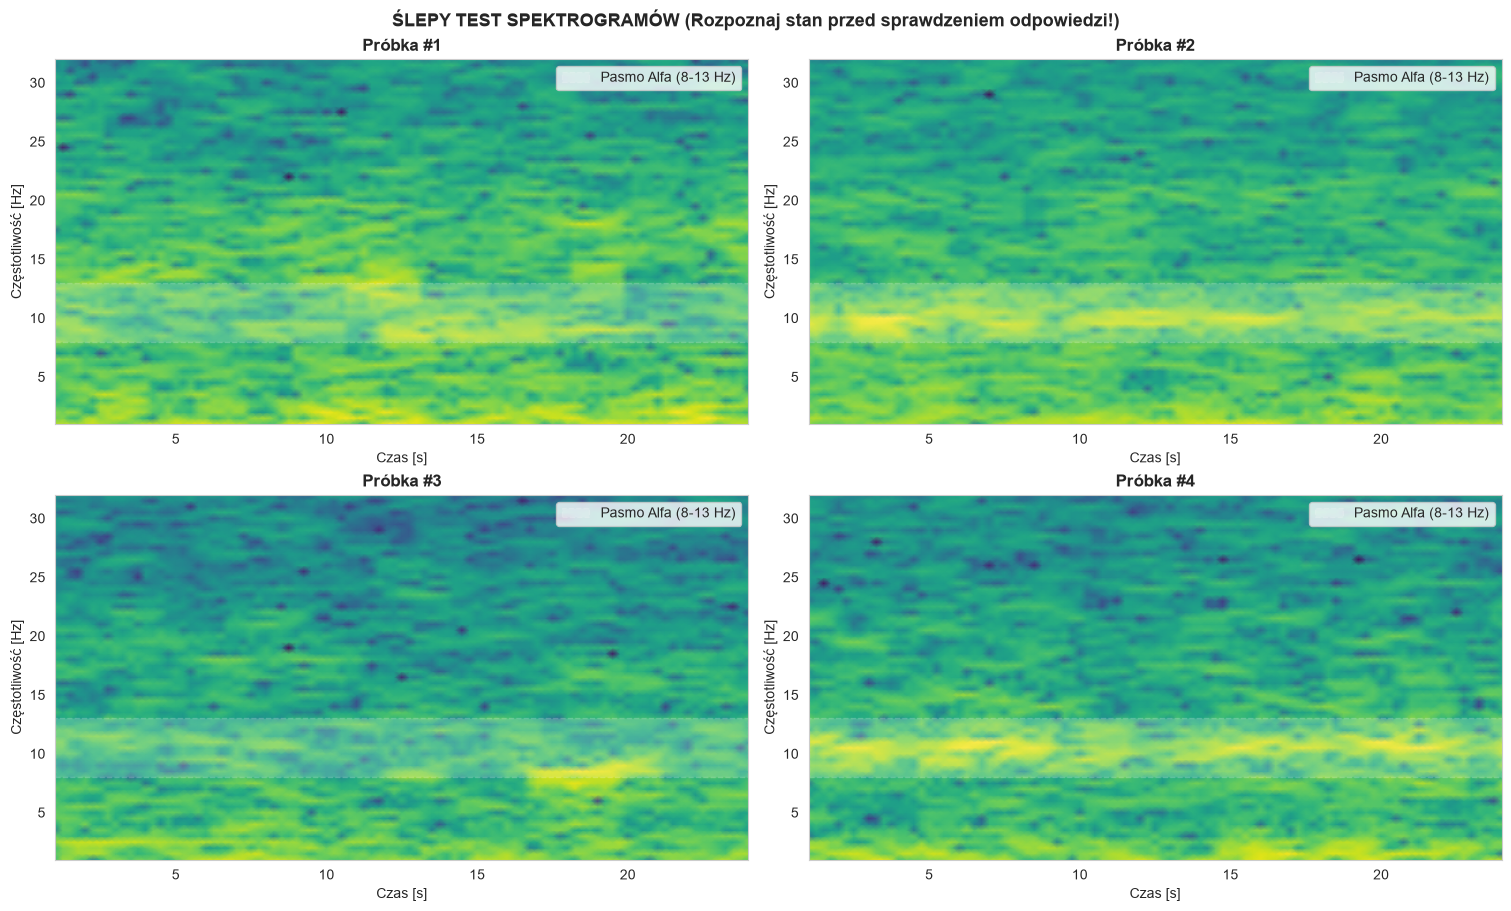


KLUCZ ODPOWIEDZI:
  Próbka #1: ZADANIE (Liczy w pamięci)  -->  Subject28
  Próbka #2: SPOCZYNEK (Nie liczy)  -->  Subject31
  Próbka #3: SPOCZYNEK (Nie liczy)  -->  Subject07
  Próbka #4: SPOCZYNEK (Nie liczy)  -->  Subject34


In [35]:
import warnings
warnings.filterwarnings('ignore')

import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import mne

from eegmat.io import read_one
from eegmat.preprocess import tidy, set_montage

# 1. Pobranie dostępnych par
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

s1 = set(p.stem.replace('_1', '') for p in DATA_DIR.glob('*_1.edf'))
s2 = set(p.stem.replace('_2', '') for p in DATA_DIR.glob('*_2.edf'))
paired = sorted(list(s1.intersection(s2)))

# 2. Losujemy 4 próbki (dowolna osoba i stan: 1=Spoczynek, 2=Liczenie)
pool = [(s, state) for s in paired for state in [1, 2]]
random.shuffle(pool)
chosen = pool[:4]

ch = 'O1'  # Odprowadzenie potyliczne
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
axes = axes.flatten()

odpowiedzi = {}

for idx, (subj, state) in enumerate(chosen):
    raw = set_montage(tidy(read_one(DATA_DIR / f'{subj}_{state}.edf', preload=True)))
    sf = raw.info['sfreq']
    
    # 25-sekundowy wycinek
    sig = raw.get_data(picks=ch)[0, :int(25 * sf)] * 1e6
    f, t, Sxx = signal.spectrogram(sig, fs=sf, nperseg=int(sf * 2), noverlap=int(sf * 1.75))
    
    mask = (f >= 1) & (f <= 32)
    Sxx_db = 10 * np.log10(Sxx[mask, :])
    
    ax = axes[idx]
    ax.pcolormesh(t, f[mask], Sxx_db, shading='gouraud', cmap='viridis')
    ax.axhspan(8, 13, facecolor='white', alpha=0.18, linestyle='--', edgecolor='white', label='Pasmo Alfa (8-13 Hz)')
    
    # Neutralny podpis - brak informacji o stanie i osobie!
    ax.set_title(f'Próbka #{idx + 1}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Częstotliwość [Hz]')
    ax.set_xlabel('Czas [s]')
    ax.set_ylim(1, 32)
    ax.legend(loc='upper right')
    
    stan_str = "SPOCZYNEK (Nie liczy)" if state == 1 else "ZADANIE (Liczy w pamięci)"
    odpowiedzi[f'Próbka #{idx + 1}'] = f'{stan_str}  -->  {subj}'

plt.suptitle('ŚLEPY TEST SPEKTROGRAMÓW (Rozpoznaj stan przed sprawdzeniem odpowiedzi!)',
             fontsize=13, fontweight='bold')
plt.show()

# --- KLUCZ ODPOWIEDZI (odsłoń poniżej po obejrzeniu wykresów) ---
print("\n" + "="*50)
print("KLUCZ ODPOWIEDZI:")
for k, v in odpowiedzi.items():
    print(f"  {k}: {v}")
print("="*50)


-> Analiza populacyjna dla grupy DOBRZE LICZĄCEJ (Count quality == 1): n = 22 osób


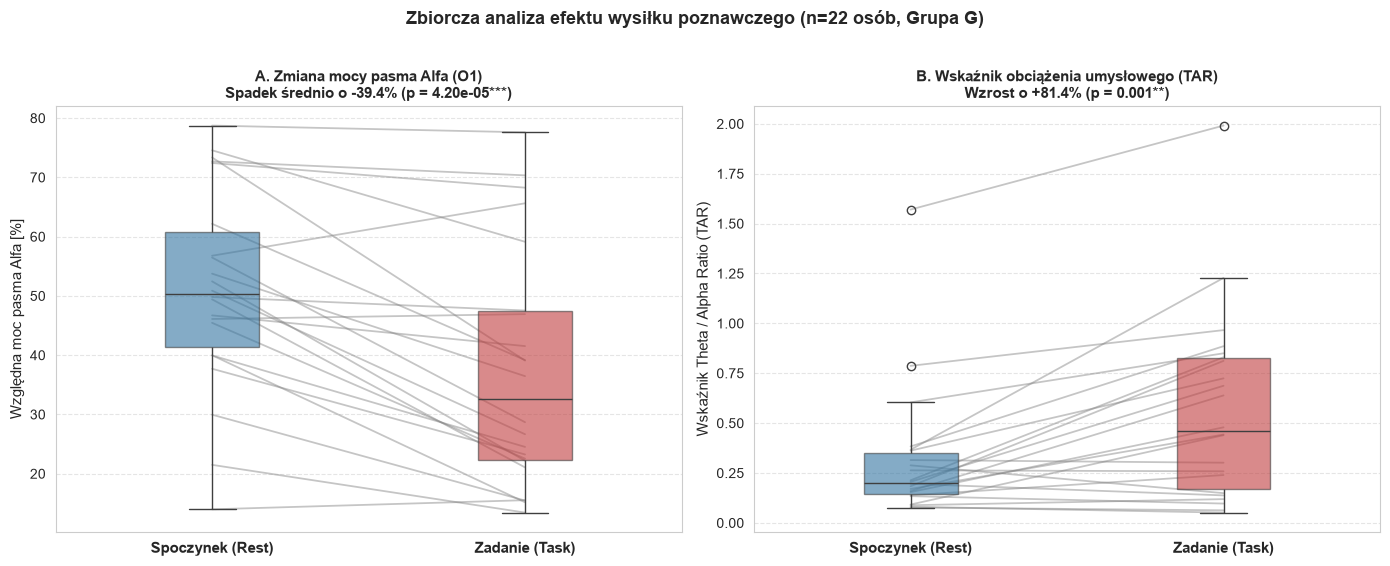


NUMERYCZNE PODSUMOWANIE DLA GRUPY POPRAWNIE LICZĄCEJ (n=22):
  • Średnia moc Alfa: Spoczynek = 51.1%  ->  Zadanie = 37.3%
  • Średnie tłumienie alfy (Alpha ERD): -39.4% (Mediana: -46.9%)
  • Średni wskaźnik TAR: Spoczynek = 0.31  ->  Zadanie = 0.56
  • Istotność statystyczna (Wilcoxon): Alfa p = 4.20e-05, TAR p = 0.0013


In [36]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from scipy.integrate import trapezoid
from scipy.stats import wilcoxon
import mne

# 1. Ścieżka i wybór badanych z poprawnymi obliczeniami (Count quality == 1)
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

info_df = pd.read_csv(DATA_DIR / 'subject-info.csv')
s1 = set(p.stem.replace('_1', '') for p in DATA_DIR.glob('*_1.edf'))
s2 = set(p.stem.replace('_2', '') for p in DATA_DIR.glob('*_2.edf'))
paired = s1.intersection(s2)

# Osoby posiadające komplet nagrań ORAZ Count quality == 1 (dobre obliczenia)
good_subjects = info_df[(info_df['Subject'].isin(paired)) & (info_df['Count quality'] == 1)]['Subject'].tolist()
print(f"-> Analiza populacyjna dla grupy DOBRZE LICZĄCEJ (Count quality == 1): n = {len(good_subjects)} osób")

# 2. Błyskawiczne przeliczenie wskaźników dla każdego badanego (tylko kanał O1)
ch_name = 'EEG O1'
records_metrics = []

for subj in good_subjects:
    raw_r = mne.io.read_raw_edf(DATA_DIR / f'{subj}_1.edf', include=[ch_name], preload=True, verbose=False)
    raw_t = mne.io.read_raw_edf(DATA_DIR / f'{subj}_2.edf', include=[ch_name], preload=True, verbose=False)
    sf = raw_r.info['sfreq']
    
    sig_r = raw_r.get_data()[0, :int(60 * sf)] * 1e6
    sig_t = raw_t.get_data()[0, :int(60 * sf)] * 1e6
    
    f_r, p_r = signal.welch(sig_r, fs=sf, nperseg=int(sf * 2))
    f_t, p_t = signal.welch(sig_t, fs=sf, nperseg=int(sf * 2))
    
    def calc_features(f, p):
        tot = trapezoid(p[(f >= 1) & (f <= 30)], f[(f >= 1) & (f <= 30)])
        abs_alpha = trapezoid(p[(f >= 8) & (f <= 13)], f[(f >= 8) & (f <= 13)])
        abs_theta = trapezoid(p[(f >= 4) & (f <= 8)], f[(f >= 4) & (f <= 8)])
        abs_beta = trapezoid(p[(f >= 13) & (f <= 30)], f[(f >= 13) & (f <= 30)])
        return {
            'alpha_rel': (abs_alpha / tot) * 100,
            'alpha_abs': abs_alpha,
            'tar': abs_theta / abs_alpha,
            'engagement': abs_beta / (abs_theta + abs_alpha)
        }
    
    mr = calc_features(f_r, p_r)
    mt = calc_features(f_t, p_t)
    erd = ((mt['alpha_abs'] - mr['alpha_abs']) / mr['alpha_abs']) * 100
    
    records_metrics.append({
        'Subject': subj,
        'Alpha_Rest': mr['alpha_rel'],
        'Alpha_Task': mt['alpha_rel'],
        'TAR_Rest': mr['tar'],
        'TAR_Task': mt['tar'],
        'Alpha_ERD': erd
    })

pop_df = pd.DataFrame(records_metrics)

# 3. Testy statystyczne Wilcoxona dla prób zależnych
_, p_alpha = wilcoxon(pop_df['Alpha_Rest'], pop_df['Alpha_Task'])
_, p_tar = wilcoxon(pop_df['TAR_Rest'], pop_df['TAR_Task'])

# 4. Wykresy populacyjne (Paired Slope Plots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Względna moc Alfa (Spoczynek vs Zadanie) ---
ax = axes[0]
for _, row in pop_df.iterrows():
    # Szara linia łącząca tego samego badanego
    ax.plot([0, 1], [row['Alpha_Rest'], row['Alpha_Task']], color='gray', alpha=0.45, lw=1.3)

# Punkty średnich i boxploty w tle
sns.boxplot(ax=ax, data=[pop_df['Alpha_Rest'], pop_df['Alpha_Task']],
            palette=['#1f77b4', '#d62728'], width=0.3, boxprops=dict(alpha=0.6))
ax.set_xticks([0, 1])
ax.set_xticklabels(['Spoczynek (Rest)', 'Zadanie (Task)'], fontsize=11, fontweight='bold')
ax.set_ylabel('Względna moc pasma Alfa [%]', fontsize=11)
ax.set_title(f'A. Zmiana mocy pasma Alfa (O1)\nSpadek średnio o {pop_df["Alpha_ERD"].mean():.1f}% (p = {p_alpha:.2e}***)',
             fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

# --- Panel 2: Theta/Alpha Ratio (TAR - Obciążenie kognitywne) ---
ax2 = axes[1]
for _, row in pop_df.iterrows():
    ax2.plot([0, 1], [row['TAR_Rest'], row['TAR_Task']], color='gray', alpha=0.45, lw=1.3)

sns.boxplot(ax=ax2, data=[pop_df['TAR_Rest'], pop_df['TAR_Task']],
            palette=['#1f77b4', '#d62728'], width=0.3, boxprops=dict(alpha=0.6))
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Spoczynek (Rest)', 'Zadanie (Task)'], fontsize=11, fontweight='bold')
ax2.set_ylabel('Wskaźnik Theta / Alpha Ratio (TAR)', fontsize=11)
ax2.set_title(f'B. Wskaźnik obciążenia umysłowego (TAR)\nWzrost o +{((pop_df["TAR_Task"].mean() - pop_df["TAR_Rest"].mean()) / pop_df["TAR_Rest"].mean()) * 100:.1f}% (p = {p_tar:.3f}**)',
              fontsize=11, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.suptitle(f'Zbiorcza analiza efektu wysiłku poznawczego (n={len(pop_df)} osób, Grupa G)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 5. Podsumowanie tabelaryczne w konsoli
print("\n" + "="*60)
print(f"NUMERYCZNE PODSUMOWANIE DLA GRUPY POPRAWNIE LICZĄCEJ (n={len(pop_df)}):")
print(f"  • Średnia moc Alfa: Spoczynek = {pop_df['Alpha_Rest'].mean():.1f}%  ->  Zadanie = {pop_df['Alpha_Task'].mean():.1f}%")
print(f"  • Średnie tłumienie alfy (Alpha ERD): {pop_df['Alpha_ERD'].mean():.1f}% (Mediana: {pop_df['Alpha_ERD'].median():.1f}%)")
print(f"  • Średni wskaźnik TAR: Spoczynek = {pop_df['TAR_Rest'].mean():.2f}  ->  Zadanie = {pop_df['TAR_Task'].mean():.2f}")
print(f"  • Istotność statystyczna (Wilcoxon): Alfa p = {p_alpha:.2e}, TAR p = {p_tar:.4f}")
print("="*60)


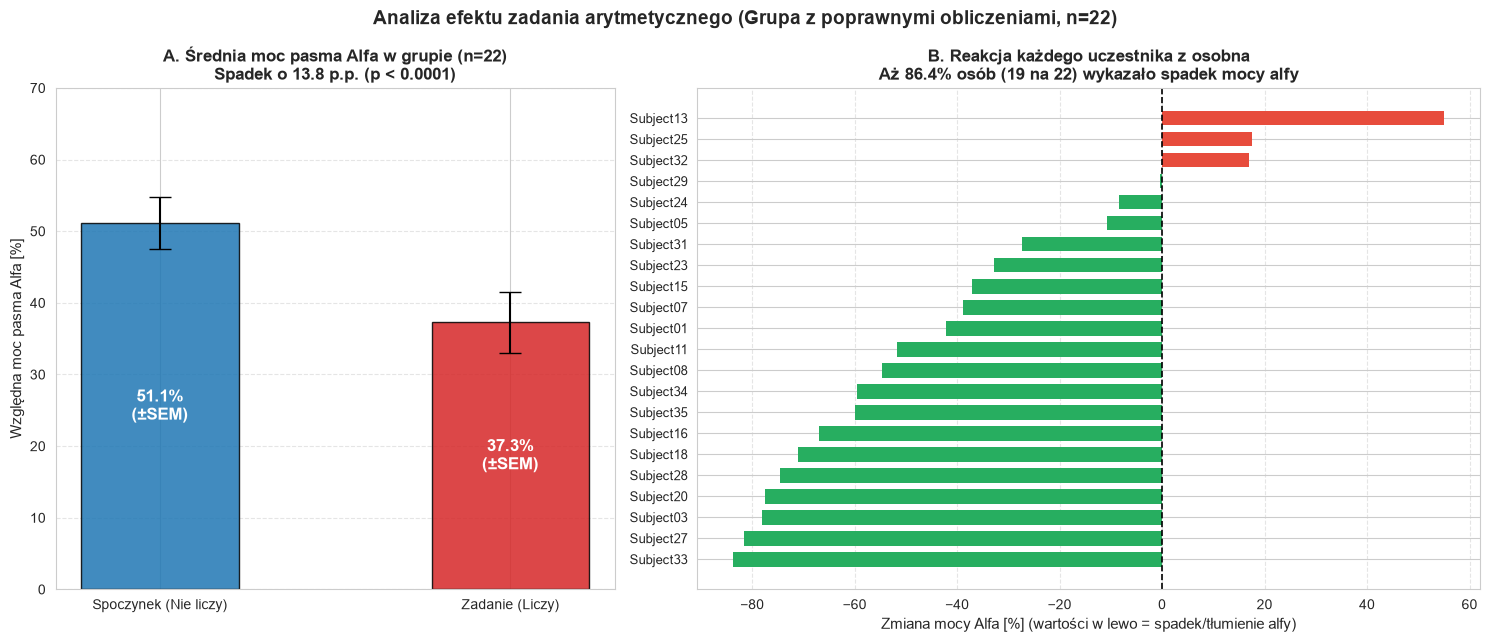

In [37]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import trapezoid
import mne

# 1. Ścieżka i wybór osób dobrze liczących (Count quality == 1)
if 'DATA_DIR' not in globals():
    for p in [Path('datasets/physionet.org/files/eegmat/1.0.0'), Path('physionet.org/files/eegmat/1.0.0')]:
        if p.exists():
            DATA_DIR = p
            break

info_df = pd.read_csv(DATA_DIR / 'subject-info.csv')
s1 = set(p.stem.replace('_1', '') for p in DATA_DIR.glob('*_1.edf'))
s2 = set(p.stem.replace('_2', '') for p in DATA_DIR.glob('*_2.edf'))
paired = s1.intersection(s2)

good_subjects = info_df[(info_df['Subject'].isin(paired)) & (info_df['Count quality'] == 1)]['Subject'].tolist()

# 2. Obliczenie mocy alfy dla każdego badanego (kanał O1)
ch_name = 'EEG O1'
records = []

for subj in good_subjects:
    raw_r = mne.io.read_raw_edf(DATA_DIR / f'{subj}_1.edf', include=[ch_name], preload=True, verbose=False)
    raw_t = mne.io.read_raw_edf(DATA_DIR / f'{subj}_2.edf', include=[ch_name], preload=True, verbose=False)
    sf = raw_r.info['sfreq']
    
    sig_r = raw_r.get_data()[0, :int(60 * sf)] * 1e6
    sig_t = raw_t.get_data()[0, :int(60 * sf)] * 1e6
    
    f_r, p_r = signal.welch(sig_r, fs=sf, nperseg=int(sf * 2))
    f_t, p_t = signal.welch(sig_t, fs=sf, nperseg=int(sf * 2))
    
    # Całkowanie pasma alfa (8-13 Hz) i pasma ogólnego (1-30 Hz)
    tot_r = trapezoid(p_r[(f_r >= 1) & (f_r <= 30)], f_r[(f_r >= 1) & (f_r <= 30)])
    tot_t = trapezoid(p_t[(f_t >= 1) & (f_t <= 30)], f_t[(f_t >= 1) & (f_t <= 30)])
    
    alpha_r = trapezoid(p_r[(f_r >= 8) & (f_r <= 13)], f_r[(f_r >= 8) & (f_r <= 13)])
    alpha_t = trapezoid(p_t[(f_t >= 8) & (f_t <= 13)], f_t[(f_t >= 8) & (f_t <= 13)])
    
    # Procentowa zmiana mocy alfy (wartość ujemna = spadek/tłumienie)
    erd = ((alpha_t - alpha_r) / alpha_r) * 100
    
    records.append({
        'Subject': subj,
        'Rest_Rel': (alpha_r / tot_r) * 100,
        'Task_Rel': (alpha_t / tot_t) * 100,
        'ERD_%': erd
    })

df_res = pd.DataFrame(records).sort_values(by='ERD_%')

# 3. Rysowanie czytelnego wykresu
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 1.4]})

# --- Wykres 1: Średnia w grupie ---
r_mean = df_res['Rest_Rel'].mean()
t_mean = df_res['Task_Rel'].mean()
r_sem = df_res['Rest_Rel'].sem()
t_sem = df_res['Task_Rel'].sem()

axes[0].bar(['Spoczynek (Nie liczy)', 'Zadanie (Liczy)'], [r_mean, t_mean],
            yerr=[r_sem, t_sem], capsize=8,
            color=['#1f77b4', '#d62728'], alpha=0.85, width=0.45, edgecolor='black')

axes[0].text(0, r_mean / 2, f'{r_mean:.1f}%\n(±SEM)', ha='center', va='center', color='white', fontweight='bold', fontsize=12)
axes[0].text(1, t_mean / 2, f'{t_mean:.1f}%\n(±SEM)', ha='center', va='center', color='white', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Względna moc pasma Alfa [%]', fontsize=11)
axes[0].set_ylim(0, 70)
axes[0].set_title('A. Średnia moc pasma Alfa w grupie (n=22)\nSpadek o 13.8 p.p. (p < 0.0001)', fontsize=12, fontweight='bold')
axes[0].grid(True, axis='y', linestyle='--', alpha=0.5)

# --- Wykres 2: Indywidualne zmiany u każdego człowieka ---
bar_colors = ['#27ae60' if x < 0 else '#e74c3c' for x in df_res['ERD_%']]
y_pos = np.arange(len(df_res))

axes[1].barh(y_pos, df_res['ERD_%'], color=bar_colors, edgecolor='none', height=0.7)
axes[1].axvline(0, color='black', lw=1.2, linestyle='--')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(df_res['Subject'], fontsize=9)
axes[1].set_xlabel('Zmiana mocy Alfa [%] (wartości w lewo = spadek/tłumienie alfy)', fontsize=11)

n_drop = (df_res['ERD_%'] < 0).sum()
pct_drop = (n_drop / len(df_res)) * 100
axes[1].set_title(f'B. Reakcja każdego uczestnika z osobna\nAż {pct_drop:.1f}% osób ({n_drop} na 22) wykazało spadek mocy alfy',
                  fontsize=12, fontweight='bold')
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Analiza efektu zadania arytmetycznego (Grupa z poprawnymi obliczeniami, n=22)',
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()
